In [ ]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



# Make the project root importable when this notebook is run from notebooks/.
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_prices, calculate_returns
from src.metrics import (
    annualized_return,
    annualized_volatility,
    sharpe_ratio as calculate_sharpe_ratio,
    max_drawdown as calculate_max_drawdown,
    cumulative_growth,
)
from src.optimizer import optimize_minimum_variance, optimize_max_sharpe

RISK_FREE_RATE = 0.04
TRADING_DAYS = 252

In [101]:
# Load historical adjusted-close prices using the reusable data loader.
data = load_prices(PROJECT_ROOT / "data" / "stocks_data.csv")

display(data.head())
print("Dataset shape:", data.shape)
print("Assets:", list(data.columns))

,AAPL,MSFT,JPM,XOM,KO
Date,,,,,
2026-06-05,307.34,416.67,312.37,149.92,79.48
2026-06-08,301.54,411.74,311.11,151.75,79.54
2026-06-09,290.55,403.41,312.70,148.91,81.34
2026-06-10,291.58,397.36,309.14,150.62,83.59
2026-06-11,295.63,390.34,313.49,146.60,82.53


Dataset shape: (100, 5)
Assets: ['AAPL', 'MSFT', 'JPM', 'XOM', 'KO']


In [102]:
data.shape
data.dtypes

AAPL    float64
MSFT    float64
JPM     float64
XOM     float64
KO      float64
dtype: object

In [103]:
data.columns
data.head()

,AAPL,MSFT,JPM,XOM,KO
Date,,,,,
2026-06-05,307.34,416.67,312.37,149.92,79.48
2026-06-08,301.54,411.74,311.11,151.75,79.54
2026-06-09,290.55,403.41,312.70,148.91,81.34
2026-06-10,291.58,397.36,309.14,150.62,83.59
2026-06-11,295.63,390.34,313.49,146.60,82.53


In [104]:
data.isnull().sum()

AAPL    0
MSFT    0
JPM     0
XOM     0
KO      0
dtype: int64

In [105]:
data.head()

,AAPL,MSFT,JPM,XOM,KO
Date,,,,,
2026-06-05,307.34,416.67,312.37,149.92,79.48
2026-06-08,301.54,411.74,311.11,151.75,79.54
2026-06-09,290.55,403.41,312.70,148.91,81.34
2026-06-10,291.58,397.36,309.14,150.62,83.59
2026-06-11,295.63,390.34,313.49,146.60,82.53


In [106]:
data.columns

Index(['AAPL', 'MSFT', 'JPM', 'XOM', 'KO'], dtype='str')

## RETURNS

In [107]:
# Calculate daily simple returns using the reusable data-loader function.
daily_returns = calculate_returns(data)

display(daily_returns.head())
print("Return rows (including the initial NaN):", len(daily_returns))

,AAPL,MSFT,JPM,XOM,KO
Date,,,,,
2026-06-05,NaN,NaN,NaN,NaN,NaN
2026-06-08,-0.018872,-0.011832,-0.004034,0.012207,0.000755
2026-06-09,-0.036446,-0.020231,0.005111,-0.018715,0.022630
2026-06-10,0.003545,-0.014997,-0.011385,0.011483,0.027662
2026-06-11,0.013890,-0.017667,0.014071,-0.026690,-0.012681


Return rows (including the initial NaN): 100


## Reusable performance metrics\nThe following cell demonstrates the functions imported from `src/metrics.py`. The same functions are also used in the walk-forward strategy evaluations below.

In [108]:
asset_metrics = pd.DataFrame({
    "Annualized Return": daily_returns.apply(annualized_return, periods=TRADING_DAYS),
    "Annualized Volatility": daily_returns.apply(annualized_volatility, periods=TRADING_DAYS),
    "Sharpe Ratio": daily_returns.apply(
        lambda series: calculate_sharpe_ratio(
            series, risk_free_rate=RISK_FREE_RATE, periods=TRADING_DAYS
        )
    ),
    "Maximum Drawdown": daily_returns.apply(calculate_max_drawdown),
})
display(asset_metrics.style.format("{:.2%}"))

,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
AAPL,34.82%,27.70%,111.27%,-11.12%
MSFT,68.41%,36.92%,174.46%,-15.32%
JPM,20.20%,18.98%,85.35%,-9.75%
XOM,49.58%,25.14%,181.34%,-10.34%
KO,37.26%,21.52%,154.53%,-6.89%


In [109]:
print(type(daily_returns))

<class 'pandas.DataFrame'>


In [110]:
daily_returns.head()

,AAPL,MSFT,JPM,XOM,KO
Date,,,,,
2026-06-05,NaN,NaN,NaN,NaN,NaN
2026-06-08,-0.018872,-0.011832,-0.004034,0.012207,0.000755
2026-06-09,-0.036446,-0.020231,0.005111,-0.018715,0.022630
2026-06-10,0.003545,-0.014997,-0.011385,0.011483,0.027662
2026-06-11,0.013890,-0.017667,0.014071,-0.026690,-0.012681


In [111]:
mean_daily_return=daily_returns.mean()
print(mean_daily_return)

AAPL    0.001382
MSFT    0.002715
JPM     0.000801
XOM     0.001968
KO      0.001479
dtype: float64


In [112]:
daily_volatility=daily_returns.std()
print(daily_volatility)

AAPL    0.017450
MSFT    0.023257
JPM     0.011954
XOM     0.015834
KO      0.013559
dtype: float64


In [113]:
annulized_mean_return=mean_daily_return*252
annulized_volatility=daily_volatility*np.sqrt(252)
print(f'annulized_mean_return are:{annulized_mean_return}')
print(f'annulized volatility are:{annulized_volatility}')

annulized_mean_return are:AAPL    0.348230
MSFT    0.684107
JPM     0.201960
XOM     0.495818
KO      0.372596
dtype: float64
annulized volatility are:AAPL    0.277007
MSFT    0.369200
JPM     0.189760
XOM     0.251364
KO      0.215237
dtype: float64


In [114]:
risk_free_rate=0.04

In [115]:
sharpe_ratio=(annulized_mean_return-risk_free_rate)/annulized_volatility
print(f'this are the sharpe ratios:{sharpe_ratio}')

this are the sharpe ratios:AAPL    1.112716
MSFT    1.744602
JPM     0.853503
XOM     1.813374
KO      1.545255
dtype: float64


In [116]:
print(type(sharpe_ratio))

<class 'pandas.Series'>


In [117]:
sharpe_ratio.iloc[1]

np.float64(1.7446021252578088)

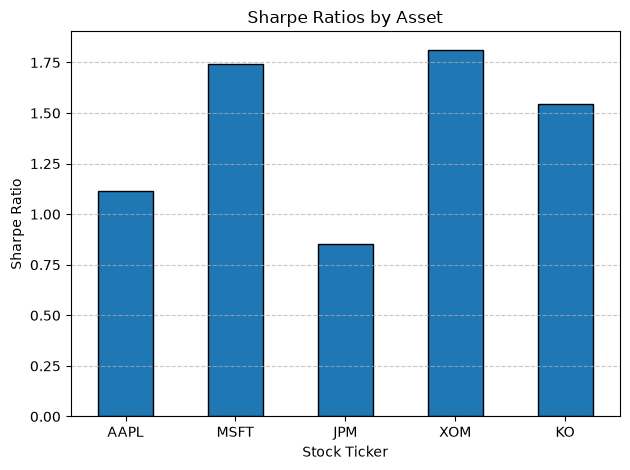

In [118]:
sharpe_ratio.plot(kind='bar', edgecolor='black')

plt.title("Sharpe Ratios by Asset")
plt.xlabel("Stock Ticker")
plt.ylabel("Sharpe Ratio")
plt.xticks(rotation=0)  # Keeps the asset names (AAPL, MSFT) upright
plt.grid(axis='y', linestyle='--', alpha=0.7)

# 3. Render the visualization
plt.tight_layout()
plt.show()

In [119]:
cumulative_returns=(1+daily_returns).cumprod() - 1

print(cumulative_returns.tail())

                AAPL      MSFT       JPM       XOM        KO
Date                                                        
2026-10-21  0.119249  0.279070  0.073054  0.187900  0.166080
2026-10-22  0.133012  0.250582  0.077376  0.188834  0.199547
2026-10-23  0.131402  0.258814  0.061498  0.222052  0.166457
2026-10-26  0.118989  0.278230  0.069373  0.230923  0.166331
2026-10-27  0.129368  0.275182  0.074975  0.200040  0.147207


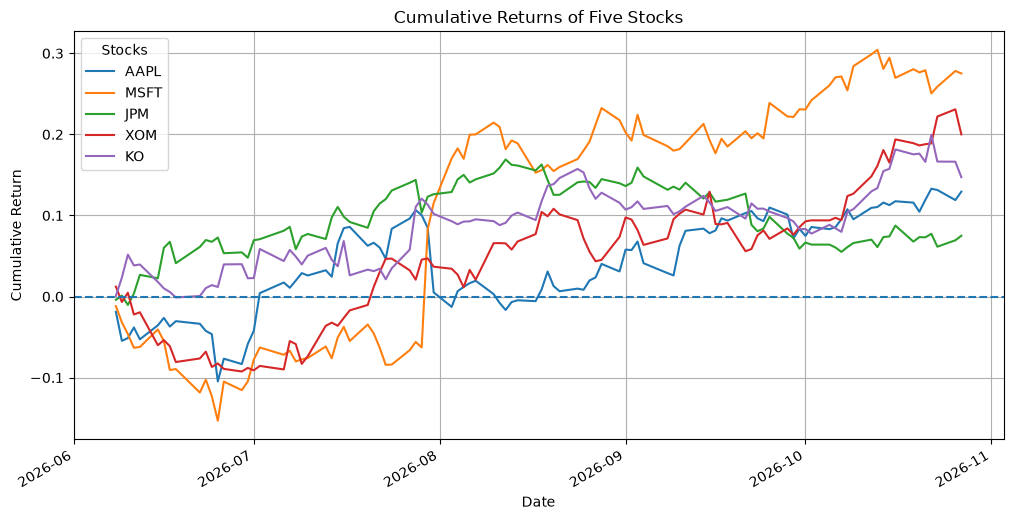

In [120]:
cumulative_returns.plot(figsize=(12, 6))

plt.title('Cumulative Returns of Five Stocks')
plt.xlabel('Date')
plt.ylabel('Cumulative Return')
plt.axhline(y=0, linestyle='--')
plt.legend(title='Stocks')
plt.grid(True)
plt.show()

## MAX DRAWDOWN

In [121]:
running_max=(1+daily_returns).cumprod().cummax()
print(running_max)

                AAPL      MSFT       JPM       XOM        KO
Date                                                        
2026-06-05       NaN       NaN       NaN       NaN       NaN
2026-06-08  0.981128  0.988168  0.995966  1.012207  1.000755
2026-06-09  0.981128  0.988168  1.001056  1.012207  1.023402
2026-06-10  0.981128  0.988168  1.001056  1.012207  1.051711
2026-06-11  0.981128  0.988168  1.003585  1.012207  1.051711
...              ...       ...       ...       ...       ...
2026-10-21  1.119249  1.304270  1.169062  1.193837  1.181429
2026-10-22  1.133012  1.304270  1.169062  1.193837  1.199547
2026-10-23  1.133012  1.304270  1.169062  1.222052  1.199547
2026-10-26  1.133012  1.304270  1.169062  1.230923  1.199547
2026-10-27  1.133012  1.304270  1.169062  1.230923  1.199547

[100 rows x 5 columns]


In [122]:
drawdown=((1+daily_returns).cumprod()/running_max) -1

In [123]:
max_drawdown=drawdown.min()
print(max_drawdown)

AAPL   -0.111239
MSFT   -0.143076
JPM    -0.097486
XOM    -0.103394
KO     -0.068921
dtype: float64


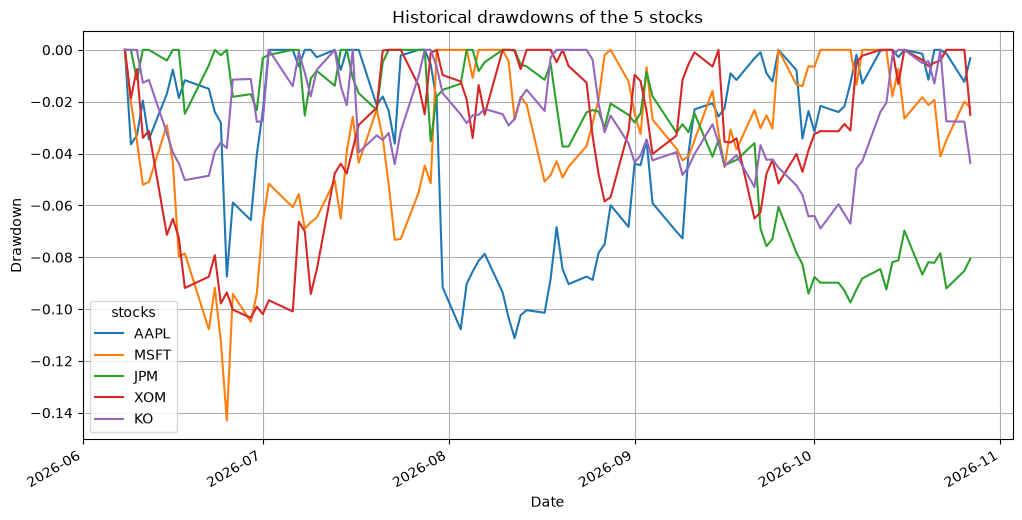

In [124]:
drawdown.plot(figsize=(12,6))
plt.title('Historical drawdowns of the 5 stocks')
plt.xlabel('Date')
plt.ylabel('Drawdown')
plt.legend(title='stocks')
plt.grid(True)
plt.show()


##  PORTFOLIO CONSTRUCTION

## 1.Equally weighted portfolio

In [125]:
## an equally weighted portfolio is one where each asset is allocated an equal amount of funds
weights=np.array([0.2,0.2,0.2,0.2,0.2])
print(sum(weights))

1.0


In [126]:
# '@' operator performs matrix multiplication.Here it computes a weighted sum of the five stocks returns for every date
portfolio_returns=daily_returns @ weights
print(portfolio_returns)

Date
2026-06-05         NaN
2026-06-08   -0.004355
2026-06-09   -0.009530
2026-06-10    0.003262
2026-06-11   -0.005815
                ...   
2026-10-21    0.001535
2026-10-22    0.004708
2026-10-23   -0.001844
2026-10-26    0.003805
2026-10-27   -0.005871
Length: 100, dtype: float64


In [127]:
portfolio_returns.head()

Date
2026-06-05         NaN
2026-06-08   -0.004355
2026-06-09   -0.009530
2026-06-10    0.003262
2026-06-11   -0.005815
dtype: float64

In [128]:
## Annualized mean return
annulized_portfolio_returns=portfolio_returns.mean()*252
print(f'annualized portfolio returns :{annulized_portfolio_returns:.2%}')

annualized portfolio returns :42.05%


In [129]:
##annualized_portfolio_volatility
annualized_portfolio_volatility=portfolio_returns.std() *np.sqrt(252)
print(f'annualized_portfolio_volatility:{annualized_portfolio_volatility:.2%}')

annualized_portfolio_volatility:12.72%


In [130]:
portfolio_sharpe=(annulized_portfolio_returns -risk_free_rate)/annualized_portfolio_volatility
print(f'portfolio sharpe:{portfolio_sharpe:.3f}')

portfolio sharpe:2.991


## COMPARING PORTFOLIO RISK WITH INDIVIDUAL STOCK RISK

In [131]:
#calculate the covariance matrix of daily revenue
cov_matrix=daily_returns.cov()
#calculate portfolio variance
portfolio_variance=weights.T @ cov_matrix @ weights
#Annualize portfolio volatility
portfolio_volatility_check=np.sqrt(portfolio_variance*252)

print('Portfolio volatility:',portfolio_volatility_check)

Portfolio volatility: 0.1272256429149265


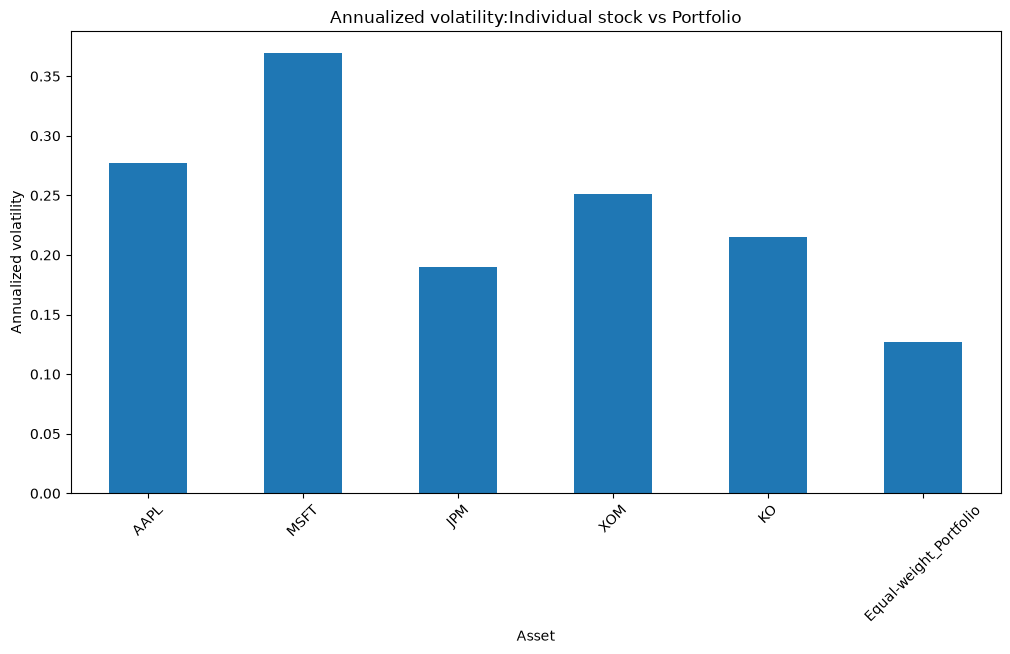

In [132]:
#comparing each stock annualized volatility to the portfolio
individual_volatility=daily_returns.std()*np.sqrt(252)

volatility_comparison=individual_volatility.copy()

volatility_comparison['Equal-weight_Portfolio']=portfolio_volatility_check

volatility_comparison.plot(kind='bar',figsize=(12,6))

plt.title('Annualized volatility:Individual stock vs Portfolio')
plt.ylabel('Annualized volatility')
plt.xlabel('Asset')
plt.xticks(rotation=45)

plt.show()

# Building the efficient frontier
 this tells what are the efficients weights for each stock

In [133]:
#lets generate 5000  random portfolios

num_portfolios=5000
num_assets=len(daily_returns.columns)
print(num_assets)

results=[]
all_weights = []

for _ in range(num_portfolios):
    #Generate random portfolios weights
    weights=np.random.random(num_assets)

    #Normalize weights so they sum to 1
    weights=weights/weights.sum()

    #Annualized portfolio return
    portfolio_return=np.sum(daily_returns.mean()*weights)*252

    #Annualized portfolio volatility
    portfolio_volatility=np.sqrt(weights.T @ daily_returns.cov()@ weights * 252)

    #Sharpe ratio
    sharpe_ratio=(portfolio_return-risk_free_rate)/portfolio_volatility

    results.append([portfolio_return,portfolio_volatility,sharpe_ratio])
    all_weights.append(weights)
portfolio_results=pd.DataFrame(results,columns=['Return','Volatility','Sharpe'])
weights_df = pd.DataFrame(all_weights,columns=daily_returns.columns)
    
print(portfolio_results.head())

5
     Return  Volatility    Sharpe
0  0.447479    0.136131  2.993283
1  0.399696    0.118634  3.031972
2  0.441011    0.136700  2.933521
3  0.366322    0.127738  2.554618
4  0.441688    0.129718  3.096616


In [134]:
print(len(portfolio_results))

5000


In [135]:
#Find the portfolio with the highest sharpe ratio
max_sharpe_portfolio=portfolio_results.loc[
    portfolio_results['Sharpe'].idxmax()
]
print(f'portfolio with the highest sharpe ratio:{max_sharpe_portfolio}')

portfolio with the highest sharpe ratio:Return        0.438123
Volatility    0.127416
Sharpe        3.124597
Name: 3308, dtype: float64


In [136]:
#to extract the weights of the portfolio with the max sharpe
best_index=portfolio_results['Sharpe'].idxmax()
best_weights=weights_df.iloc[best_index]

print('Optimal portfolio weights:')
print(best_weights)

print('\nTotal weight:',best_weights.sum())

Optimal portfolio weights:
AAPL    0.104826
MSFT    0.201776
JPM     0.191625
XOM     0.307767
KO      0.194006
Name: 3308, dtype: float64

Total weight: 1.0


## Visualization of the Allocation

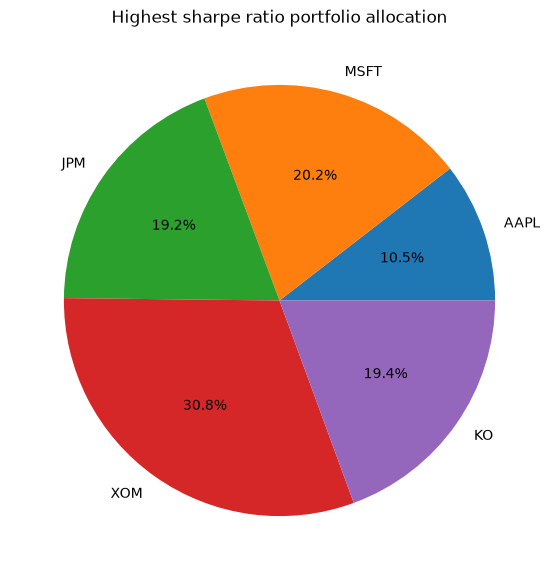

In [137]:
best_weights.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7,7),
    ylabel='',
    title='Highest sharpe ratio portfolio allocation'
)
plt.show()

## Visualization of all 5000 portfolios(OPPORTUNITY SET)
# plotting risk against return and highlighting the portfolio with the highest sharpe ratio

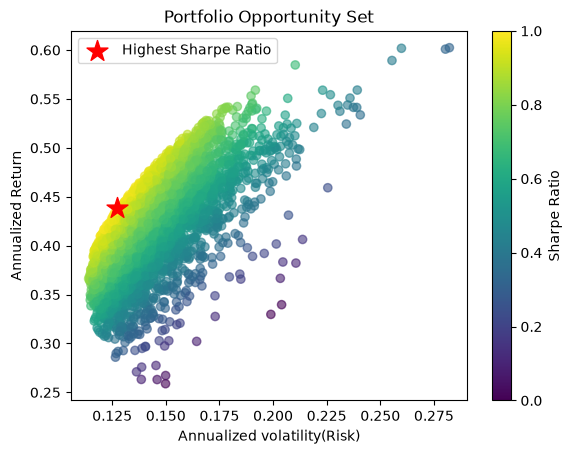

In [138]:
plt.Figure(figsize=(12,6))

plt.scatter(
    portfolio_results['Volatility'],
    portfolio_results['Return'],
    c=portfolio_results['Sharpe'],
    cmap='viridis',
    alpha=0.6

)

plt.scatter(
    portfolio_results.loc[best_index,'Volatility'],
    portfolio_results.loc[best_index,'Return'],
    color='red',
    marker='*',
    s=250,
    label='Highest Sharpe Ratio'

)

plt.xlabel('Annualized volatility(Risk)')
plt.ylabel('Annualized Return')
plt.title('Portfolio Opportunity Set')
plt.colorbar(label='Sharpe Ratio')
plt.legend()
plt.show()

In [139]:
##Lets identify the efficient frontier
#1.sort portfolios by volatility
sorted_portfolios=portfolio_results.sort_values(
    by='Volatility'
).copy()

#2.keep track of the highest return seen so far
sorted_portfolios['Best_return_so_far']=(
    sorted_portfolios['Return'].cummax()
)

#3.Identify portfolios on the approximate efficient frontier

efficient_portfolios=sorted_portfolios[
    sorted_portfolios['Return']
    >= sorted_portfolios['Best_return_so_far']]


print(efficient_portfolios.head())




        Return  Volatility    Sharpe  Best_return_so_far
2408  0.366128    0.114016  2.860373            0.366128
739   0.368167    0.114360  2.869585            0.368167
1414  0.370720    0.114737  2.882420            0.370720
3914  0.375616    0.115001  2.918368            0.375616
432   0.377309    0.115633  2.917082            0.377309


## Lets visualize the Efficient Frontier

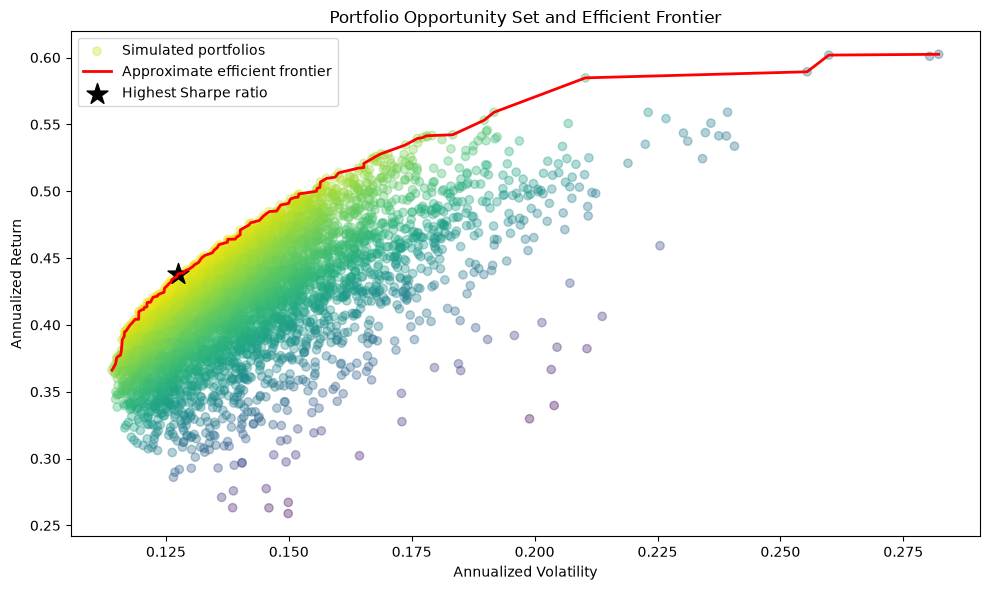

In [140]:
plt.figure(figsize=(10, 6))

# All simulated portfolios
plt.scatter(
    portfolio_results["Volatility"],
    portfolio_results["Return"],
    c=portfolio_results["Sharpe"],
    cmap="viridis",
    alpha=0.35,
    label="Simulated portfolios"
)

# Approximate efficient frontier
plt.plot(
    efficient_portfolios["Volatility"],
    efficient_portfolios["Return"],
    color="red",
    linewidth=2,
    label="Approximate efficient frontier"
)

# Highest-Sharpe portfolio
plt.scatter(
    portfolio_results.loc[best_index, "Volatility"],
    portfolio_results.loc[best_index, "Return"],
    color="black",
    marker="*",
    s=250,
    label="Highest Sharpe ratio"
)

plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Return")
plt.title("Portfolio Opportunity Set and Efficient Frontier")
plt.legend()
plt.tight_layout()
plt.show()

In [141]:
##Lets look for a portfolio with the least volatility
min_vol_index=portfolio_results['Volatility'].idxmin()
min_vol_portfolio=portfolio_results.loc[min_vol_index]
min_vol_weights=weights_df.loc[min_vol_index]

print("Minimum-Volatility Portfolio")
print(min_vol_portfolio)

print("\nPortfolio Weights")
print(min_vol_weights)

Minimum-Volatility Portfolio
Return        0.366128
Volatility    0.114016
Sharpe        2.860373
Name: 2408, dtype: float64

Portfolio Weights
AAPL    0.120286
MSFT    0.110457
JPM     0.366996
XOM     0.200266
KO      0.201995
Name: 2408, dtype: float64


In [142]:
#lets look at the portfolio with highest return
max_return_index=portfolio_results['Return'].idxmax()
max_return_portfolio=portfolio_results.loc[max_return_index]
max_return_weights=weights_df.loc[max_return_index]

print("Maximum return Portfolio")
print(max_sharpe_portfolio)

print("\nPortfolio Weights")
print(max_return_weights)

Maximum return Portfolio
Return        0.438123
Volatility    0.127416
Sharpe        3.124597
Name: 3308, dtype: float64

Portfolio Weights
AAPL    0.084578
MSFT    0.753570
JPM     0.069643
XOM     0.073173
KO      0.019037
Name: 4600, dtype: float64


In [ ]:
##Lets verify that the minimum volatility portfolio really has lower volatility than our equal weight portfolio
equal_weight_volatility=annualized_portfolio_volatility
min_volatility=min_vol_portfolio['Volatility']

print(f'Equal-weight_volatility:{equal_weight_volatility:.2%}')
print(f'Minimum-volatility portfolio:{min_volatility:.2%}')

reduction=(
    (equal_weight_volatility - min_volatility)/equal_weight_volatility
)
print(f'volatility reduction:{reduction:.2%}')

Equal-weight_volatility:12.72%
Minimum-volatility portfolio:11.40%
volatility reduction:10.38%


## Examine Diversification

In [ ]:
correlation_matrix=daily_returns.corr()
print(correlation_matrix.round(2))

      AAPL  MSFT   JPM   XOM    KO
AAPL  1.00  0.13  0.01 -0.07  0.18
MSFT  0.13  1.00  0.05 -0.10  0.04
JPM   0.01  0.05  1.00 -0.04 -0.03
XOM  -0.07 -0.10 -0.04  1.00  0.16
KO    0.18  0.04 -0.03  0.16  1.00


In [ ]:
print(cov_matrix)

          AAPL      MSFT       JPM       XOM        KO
AAPL  0.000304  0.000054  0.000001 -0.000019  0.000044
MSFT  0.000054  0.000541  0.000015 -0.000038  0.000013
JPM   0.000001  0.000015  0.000143 -0.000007 -0.000005
XOM  -0.000019 -0.000038 -0.000007  0.000251  0.000034
KO    0.000044  0.000013 -0.000005  0.000034  0.000184


 The stocks haven't moved in perfect synchrony. When you combine them, some of their daily movements can offset one another, reducing the portfolio's overall volatility.

 For example, AAPL and XOM have a correlation of −0.07. Their returns have a slightly negative linear relationship in your sample, so their movements may sometimes help offset each other

In [ ]:
print(cov_matrix.loc['AAPL','XOM'])

-1.8868426628634858e-05


In [ ]:
aapl_xom_cov = daily_returns["AAPL"].cov(
    daily_returns["XOM"]
)

aapl_std = daily_returns["AAPL"].std()
xom_std = daily_returns["XOM"].std()

aapl_xom_corr = aapl_xom_cov / (aapl_std * xom_std)

print("Covariance:", aapl_xom_cov)
print("AAPL daily standard deviation:", aapl_std)
print("XOM daily standard deviation:", xom_std)
print("Correlation:", aapl_xom_corr)

Covariance: -1.8868426628634855e-05
AAPL daily standard deviation: 0.017449822111208175
XOM daily standard deviation: 0.0158344681535609
Correlation: -0.06828749826528795


## PORTFOLIO OPTIMIZATION
 Portfolio optimization is the process of choosing how much money to allocate to different assets to achieve a particular investment objective while accounting for risk.

## Minimum variance portfolio


In [ ]:
## we will start with a equal weight portfolio
from scipy.optimize import minimize

In [ ]:
#number of assets
num_assets=len(daily_returns.columns)
cov_matrix=daily_returns.cov()

# initial equal weights
initial_weights=np.repeat(1/num_assets,num_assets)

print('Number of assets:',num_assets)
print('Initial weights:',initial_weights)
print('Sum of weights:',initial_weights.sum())

Number of assets: 5
Initial weights: [0.2 0.2 0.2 0.2 0.2]
Sum of weights: 1.0


In [ ]:
## lets annulize the covariance matrix
cov_matrix=daily_returns.cov()*252
print(cov_matrix.iloc[0,0])

0.07673306551162803


In [ ]:
def portfolio_variance(weights):
    return weights.T @ cov_matrix @weights

In [ ]:
constraints=[
    {
        'type':'eq','fun':lambda weights:np.sum(weights)-1
    }
]
bounds=tuple((0,1)for _ in range(num_assets))

In [ ]:
result=minimize(
    portfolio_variance,
    initial_weights,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)
optimal_weights=result.x

print('Optimization successful:',result.success)
print('Optimal weights:',optimal_weights)
print('sum of weights:',optimal_weights.sum())

Optimization successful: True
Optimal weights: [0.12982547 0.08203041 0.36437571 0.21119936 0.21256904]
sum of weights: 1.0


In [ ]:
print('Minimum variance:',result.fun)

Minimum variance: 0.012860622345276348


 Notice something interesting: JPM receives the largest allocation, while MSFT receives the smallest.

 The optimizer is choosing these weights to minimise portfolio variance, taking into account both individual stock volatility and how the stocks move relative to one another.

## Let's calculate the portfolio's actual risk and return

In [ ]:
optimal_return=np.sum(daily_returns.mean()* optimal_weights)*252

optimal_volatility=np.sqrt(
    optimal_weights.T @ cov_matrix@ optimal_weights
)

optimal_sharpe =(optimal_return-risk_free_rate)/optimal_volatility

print('Annulized return:',optimal_return)
print('Annualized volatility',optimal_volatility)
print('Sharpe ratio',optimal_sharpe)

Annulized return: 0.35883489891735015
Annualized volatility 0.11340468396532988
Sharpe ratio 2.8114791009410554


 Three observations:

 Lower risk: Volatility fell from 12.72% to 11.34%.
 Lower expected return: The historical annualized return fell from 42.05% to 35.88%.
 Slightly lower Sharpe ratio: The equal-weight portfolio had a higher historical risk-adjusted return.

## Maximum Sharpe Ratio Portfolio

In [ ]:
def negative_sharpe(weights):
    portfolio_return=np.sum(daily_returns.mean()*weights)*252
    portfolio_volatility=np.sqrt( weights.T @ cov_matrix @ weights)
    sharpe_ratio = (portfolio_return -0.04)/portfolio_volatility

    return -sharpe_ratio

 since the scipy.minimize is designed to minimise an objective,but we want to maximize the sharpe ratio ,so we use this mathematical trick :max(SR)=min(−SR)

In [ ]:
sharpe_result=minimize(
    negative_sharpe,
    initial_weights,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)
sharpe_weights=sharpe_result.x

print('Optimization successful:',sharpe_result.success)
print('Optimal weights:',sharpe_weights)
print('Sum of weights:',sharpe_weights.sum())

Optimization successful: True
Optimal weights: [0.11856689 0.19148346 0.18347339 0.30873879 0.19773747]
Sum of weights: 1.0


In [ ]:
optimal_sharpe_return=np.sum(daily_returns.mean()*sharpe_weights)*252
optimal_sharpe_volatility=np.sqrt(sharpe_weights.T @ cov_matrix @ sharpe_weights)
max_sharpe=(optimal_sharpe_return-0.04)/optimal_sharpe_volatility


print(f'max sharpe return:{optimal_sharpe_return:.2%}')
print(f'max sharpe voatility:{optimal_sharpe_volatility:.2%}')
print('Max sharpe portfolio:',max_sharpe)

max sharpe return:43.61%
max sharpe voatility:12.67%
Max sharpe portfolio: 3.127426356736084


## TARGET RETURN PORTFOLIO OPTIMIZATION

 1. What is a target-return portfolio?

 Imagine you decide:

I want my portfolio to generate at least 40% annualized return. Among all portfolios that can achieve this, I want the one with the lowest possible risk.

 That's the target-return approach.

In [ ]:
##This is our constraint
target_return=0.40

In [ ]:
def portfolio_retrn(weights):
    return np.sum(daily_returns.mean()*weights)* 252

constraint_s=[
    { 'type':'eq','fun':lambda weights:np.sum(weights) -1},
{'type':'ineq','fun':lambda weights:portfolio_retrn(weights)-target_return
    }
]

eq: weights must add up to exactly 1.
 ineq: portfolio return minus target return must be greater than or equal to zero.

In [ ]:
## We already have our objective function, portfolio_variance, and our long-only bounds
target_result=minimize(
portfolio_variance,
initial_weights,
method='SLSQP',
bounds=bounds,
constraints=constraint_s
)

target_weights=target_result.x


print('Optimization successful:',target_result.success)
print('Optimal weights:',target_weights)
print('Sum of weights:',target_weights.sum())

Optimization successful: True
Optimal weights: [0.12518383 0.13934588 0.26578956 0.26293795 0.20674277]
Sum of weights: 1.0


In [ ]:
target_return_portfolio_return=portfolio_retrn(target_weights)
target_return_volatility=np.sqrt(
    target_weights.T @ cov_matrix @ target_weights
)
target_return_sharpe= (
    target_return_portfolio_return - 0.04
)/target_return_volatility

print("Annualized Return:", target_return_portfolio_return)
print("Annualized Volatility:", target_return_volatility)
print("Sharpe Ratio:", target_return_sharpe)

Annualized Return: 0.399999999979396
Annualized Volatility: 0.11742644993528054
Sharpe Ratio: 3.0657488170493927


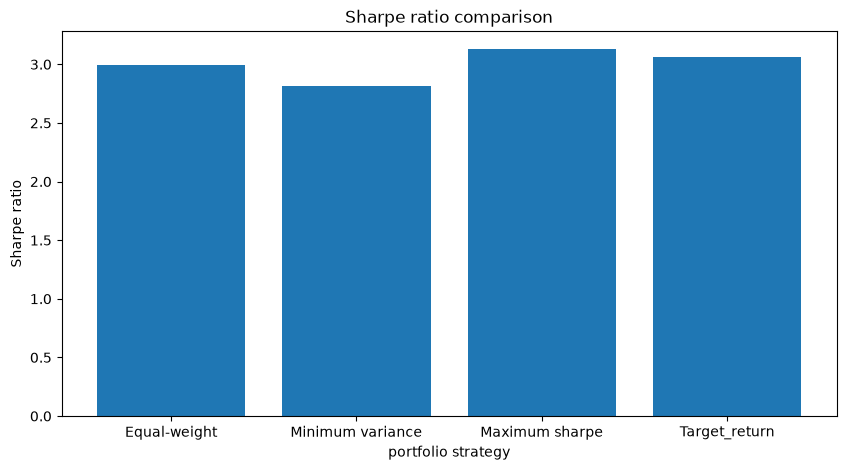

In [ ]:
sharpe_ratios={
    'Equal-weight':2.9911,
    'Minimum variance':2.8115,
    'Maximum sharpe': 3.1274,
    'Target_return':3.0657
}

plt.figure(figsize=(10,5))
plt.bar(
    sharpe_ratios.keys(),
    sharpe_ratios.values()
)
plt.title('Sharpe ratio comparison')
plt.xlabel('portfolio strategy')
plt.ylabel('Sharpe ratio')

plt.show()

In [ ]:
portfolio_results.head()

,Return,Volatility,Sharpe
0,0.447479,0.136131,2.993283
1,0.399696,0.118634,3.031972
2,0.441011,0.136700,2.933521
3,0.366322,0.127738,2.554618
4,0.441688,0.129718,3.096616


## visualization of the relationship between risk and return.

C:\Users\PC\AppData\Local\Temp\ipykernel_7668\3720370784.py:3: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


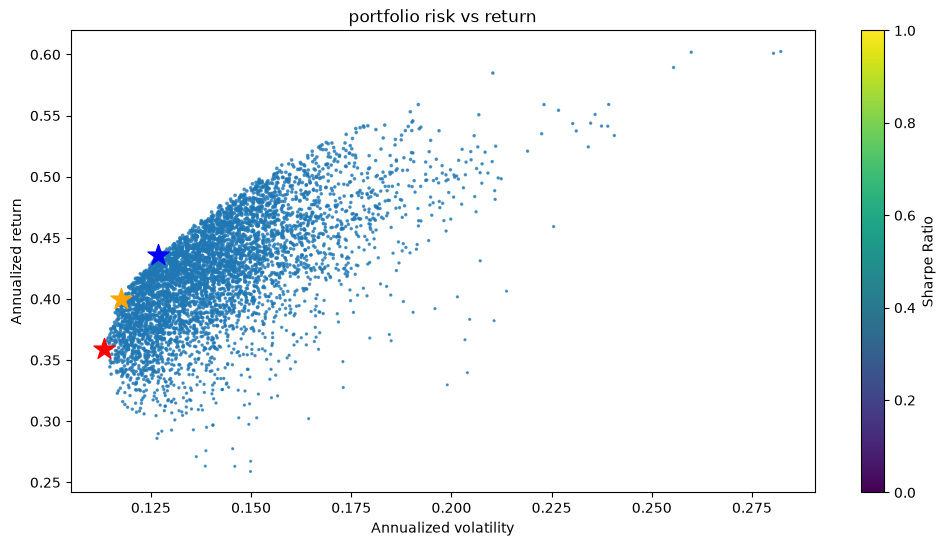

In [ ]:
plt.figure(figsize=(12,6))

plt.scatter(
    portfolio_results['Volatility'],
    portfolio_results['Return'],
    portfolio_results['Sharpe'],
    cmap='viridis',
    alpha=0.7
)
# Minimum Variance Portfolio
plt.scatter(
    optimal_volatility,
    optimal_return,
    color="red",
    marker="*",
    s=250,
    label="Minimum Variance"
)

# Maximum Sharpe Portfolio
plt.scatter(
    optimal_sharpe_volatility,
    optimal_sharpe_return,
    color="blue",
    marker="*",
    s=250,
    label="Maximum Sharpe"
)

# Target Return Portfolio
plt.scatter(
    target_return_volatility,
    target_return_portfolio_return,
    color="orange",
    marker="*",
    s=250,
    label="Target Return"
)
plt.colorbar(label='Sharpe Ratio')
plt.title('portfolio risk vs return')
plt.xlabel('Annualized volatility')
plt.ylabel('Annualized return')

plt.show()


## DRAWING THE EFFICIENT FRONTIER

In [ ]:
##Instead of choosing just one target (40%), we'll test several targets.
target_returns=np.linspace(0.3588,0.6841,50)
##This generates 50 target returns between 35.88% and 68.41%.

# np.linspace() distributes the values evenly across that range.

In [ ]:
frontier_volatility = []
frontier_returns = []

for target in target_returns:

    constraints = [
        {"type": "eq", "fun": lambda weights: np.sum(weights) - 1},
        {"type": "ineq", "fun": lambda weights: portfolio_retrn(weights) - target}
    ]

    result = minimize(
        portfolio_variance,
        initial_weights,
        method="SLSQP",
        bounds=bounds,
        constraints=constraints
    )

    if result.success:
        opt_return = portfolio_retrn(result.x)
        frontier_returns.append(opt_return)

        volatility = np.sqrt(
            result.x.T @ cov_matrix @ result.x
        )

        frontier_volatility.append(volatility)


##  What's happening here?

#For every target return:
#    The optimizer finds weights that satisfy the target.
#    It minimizes portfolio variance.
#    We calculate the resulting volatility.
#    We save the return and volatility.

#    We repeat this 50 times.     

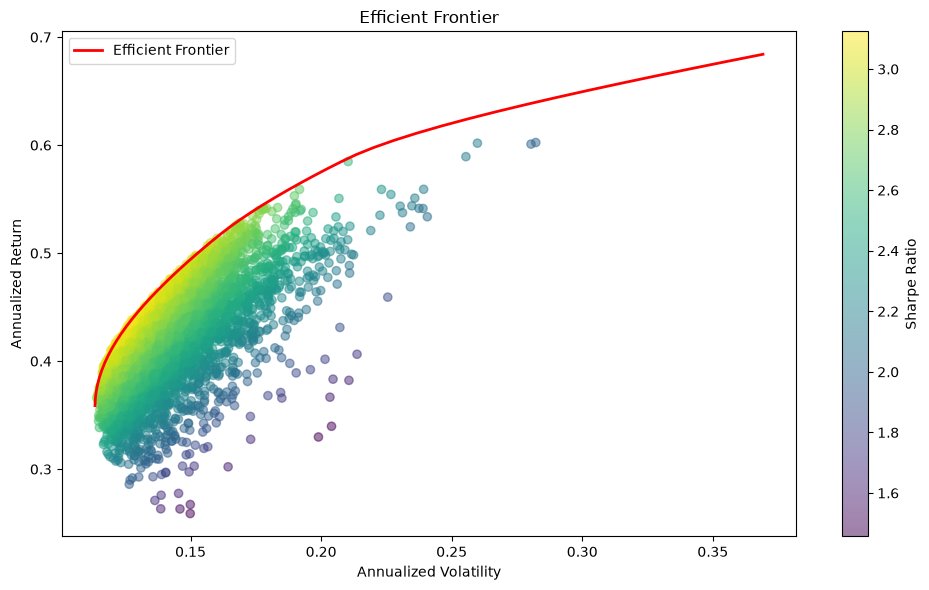

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    portfolio_results["Volatility"],
    portfolio_results["Return"],
    c=portfolio_results["Sharpe"],
    cmap="viridis",
    alpha=0.5
)

plt.plot(
    frontier_volatility,
    frontier_returns,
    color="red",
    linewidth=2,
    label="Efficient Frontier"
)

plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Return")
plt.title("Efficient Frontier")
plt.colorbar(label="Sharpe Ratio")
plt.legend()

plt.tight_layout()
plt.show()

## CAPITAL MARKETS LINE(CML)

 The key idea is that we can combine:

 A risk-free asset (such as a Treasury bill).
 A risky portfolio, typically the maximum-Sharpe portfolio.

 This combination allows us to adjust overall portfolio risk while maintaining exposure to the risky portfolio.

In [ ]:
risk_weight=0.7
risk_free_weight=0.3

combined_return=(risk_weight*optimal_sharpe_return + 
                 risk_free_weight*risk_free_rate)
combined_volatility=(
    risk_weight*optimal_sharpe_volatility
)

print('combined_return:',combined_return)
print('combined volatility:',combined_volatility)

combined_return: 0.31726465767706746
combined volatility: 0.08865585502273272


In [ ]:
## now lets calculate the new sharpe ratio
combined_sharpe=(combined_return-risk_free_rate)/combined_volatility

print('New sharpe ratio is:',combined_sharpe)

New sharpe ratio is: 3.1274263567360845


 What have we discovered?

 You can adjust your portfolio's risk exposure without changing its Sharpe ratio, provided you combine the risk-free asset with the same optimal risky portfolio under these assumptions.

## Visualize the capital market line(CML)

In [ ]:
## generate points for the CML
cml_volatility=np.linspace(0,optimal_sharpe_volatility,100)

cml_returns=(
    0.04 + max_sharpe*cml_volatility
)

print('first return:',cml_returns[0])
print('last_return:',cml_returns[-1])

first return: 0.04
last_return: 0.4360923681100964


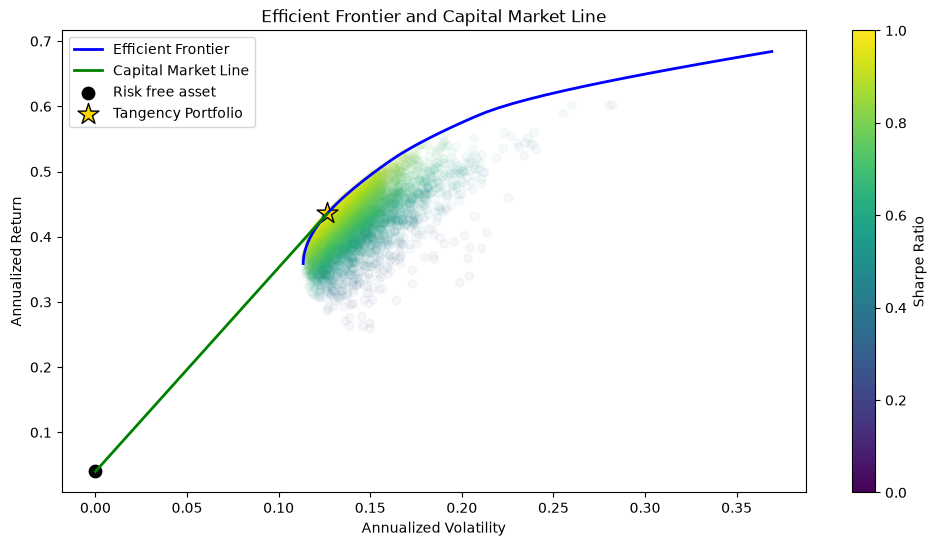

In [ ]:
## PLOT THE CML ALONGSIDE THE EFFICIENT FRONTIER
plt.figure(figsize=(12,6))

#Random portfolios
plt.scatter(
    portfolio_results['Volatility'],
    portfolio_results['Return'],
    c=portfolio_results['Sharpe'],
    cmap='viridis',
    alpha=0.04
)
#efficient frontier
plt.plot(
    frontier_volatility,
    frontier_returns,
    color='blue',
    linewidth=2,
    label='Efficient Frontier'
)
#Capital market line
plt.plot(
    cml_volatility,
    cml_returns,
    color='green',
    linewidth=2,
    label='Capital Market Line'

)

#risk free asset
plt.scatter(0,0.04,color='black',s=80,label='Risk free asset')

#Maximum sharpe portfolio

plt.scatter(
    optimal_sharpe_volatility,
    optimal_sharpe_return,
    color="gold",
    edgecolors="black",
    marker="*",
    s=250,
    label="Tangency Portfolio"
)

plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Return")
plt.title("Efficient Frontier and Capital Market Line")
plt.colorbar(label="Sharpe Ratio")
plt.legend()

plt.show()




## PORTFOLIO PERFORMANCE EVALUATION AND BACKTESTING

##  Split the data into training and testing periods

In [ ]:
split_index = int(len(daily_returns) * 0.7)

train_returns = daily_returns.iloc[:split_index]
test_returns = daily_returns.iloc[split_index:]

print("Training observations:", len(train_returns))
print("Testing observations:", len(test_returns))

Training observations: 70
Testing observations: 30


In [ ]:
print(constraints)

[{'type': 'eq', 'fun': <function <lambda> at 0x000001D6DAAD84A0>}, {'type': 'ineq', 'fun': <function <lambda> at 0x000001D6DAADB9C0>}]


## Optimize using training data

In [ ]:
train_cov_matrix=train_returns.cov()*252

def train_portfolio_return(weights):
    return np.sum(train_returns.mean()*weights)*252

def train_negative_sharpe(weights):
    portfolio_return=train_portfolio_return(weights)
    portfolio_volatility=np.sqrt(weights.T @ train_cov_matrix @ weights)
    sharpe_ratio= (portfolio_return -0.04) / portfolio_volatility

    return -sharpe_ratio



train_result=minimize(
    train_portfolio_return,
    initial_weights,
    method='SLSQP',
    bounds=bounds,
    constraints=constraints
)

train_optimal_weights=train_result.x

print('Optimization successful:',train_result.success)
print('Training optimal weights:',train_optimal_weights)
print('Sum of weights:',train_optimal_weights.sum())

Optimization successful: True
Training optimal weights: [9.43689571e-16 9.99963628e-01 8.60422844e-16 3.63717735e-05
 3.05311332e-16]
Sum of weights: 1.0


## Test the portfolio on unseen data

In [ ]:
test_portfolio_returns=test_returns @ train_optimal_weights
test_return= test_portfolio_returns.mean()*252
test_volatility=test_portfolio_returns.std()*np.sqrt(252)
test_sharpe=(test_return-0.04)/test_volatility

print('Testing annualized return:',test_return)
print('Testing annualized volatility:',test_volatility)
print('Testing Sharpe ratio:',test_sharpe)

Testing annualized return: 0.5814366984896479
Testing annualized volatility: 0.21268800361640683
Testing Sharpe ratio: 2.5456851786815173


## To compare training and test performance

In [177]:
train_portfolio_returns=train_returns @ train_optimal_weights
train_return=train_portfolio_returns.mean()*252
train_volatility=train_portfolio_returns.std()*np.sqrt(252)
train_sharpe=(train_return-0.04)/train_volatility


print("Training annualized return:", train_return)
print("Training annualized volatility:", train_volatility)
print("Training Sharpe ratio:", train_sharpe)

Training annualized return: 0.7287362213119648
Training annualized volatility: 0.4208455430201529
Training Sharpe ratio: 1.6365534404126585


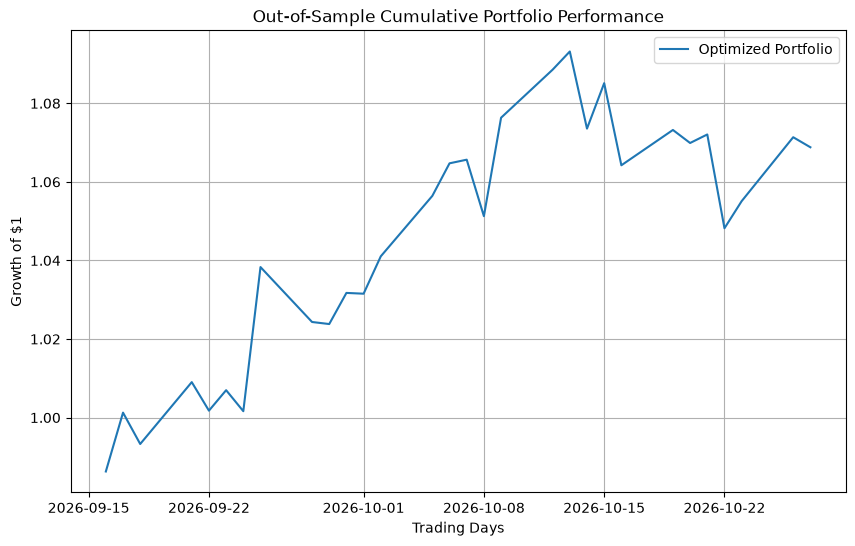

In [178]:
cumulative_returns = (1 + test_portfolio_returns).cumprod()

plt.figure(figsize=(10, 6))
plt.plot(cumulative_returns, label="Optimized Portfolio")
plt.title("Out-of-Sample Cumulative Portfolio Performance")
plt.xlabel("Trading Days")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True)
plt.show()

## Maximum Drawdown

In [ ]:
running_max = cumulative_returns.cummax()

drawdown = (cumulative_returns - running_max) / running_max

portfolio_max_drawdown = drawdown.min()

print("Portfolio Maximum Drawdown:", portfolio_max_drawdown)
print("Portfolio Maximum Drawdown (%):", portfolio_max_drawdown * 100)

Portfolio Maximum Drawdown: -0.04116057548618627
Portfolio Maximum Drawdown (%): -4.116057548618627


## Calmar Ratio

# The Calmar Ratio evaluates returns relative to maximum drawdown.
# Calmar ratio = Annualized return/ abs(maximum drawdown)

In [180]:
calmar_ratio=test_return/abs(portfolio_max_drawdown)

print('Calmar ratio:',calmar_ratio)

Calmar ratio: 14.126058531051914


## A higher Calmar Ratio indicates more annualized return relative to the worst observed peak-to-trough decline

## Sortino Ratio and Downside deviation

## 1.Downside Deviation
# Standard deviation measures how much returns fluctuate, whether upward or downward.
# Downside deviation focuses only on returns below a chosen minimum acceptable return (MAR).
# we'll use the risk-free rate of 4% annually as our minimum acceptable return.

In [ ]:
daily_target= 0.04/252

downside_returns=np.minimum(test_portfolio_returns - daily_target,0)
downside_deviation=np.sqrt(
    np.mean(downside_returns **2)
) * np.sqrt(252)

print('Annualized downside deviation:',downside_deviation)

Annualized downside deviation: 0.127682799334672


## 2.Sortino Ratio
# The Sortino ratio measures excess return relative to downside risk. Unlike the Sharpe ratio, it doesn't penalize positive volatility

In [182]:
sortino_ratio=(test_return - 0.04)/downside_deviation

print('Sortino Ratio:',sortino_ratio)

Sortino Ratio: 4.240482675121157


## Compare to a benchmark like S&P 500

In [183]:
##First lets establish the benchmark data
benchmark=yf.download(
    'SPY',
    start=test_returns.index.min(),
    end=test_returns.index.max()+pd.Timedelta(days=1),
    auto_adjust=True
)

[*********************100%***********************]  1 of 1 completed


In [ ]:
benchmark_returns=benchmark['Close'].pct_change().dropna()

In [ ]:
print(benchmark_returns.head())
print(benchmark_returns.shape)

Ticker           SPY
Date                
2026-09-17  0.011339
2026-09-18  0.001287
2026-09-21  0.015505
2026-09-22 -0.000155
2026-09-23 -0.007202
(29, 1)


# we'll align both datasets so we're comparing exactly the same trading days

In [186]:
comparison=pd.concat([test_portfolio_returns,benchmark_returns],
                     axis=1,
                     join='inner')

comparison.columns=['Portfolio','SPY']

print(comparison.head())
print(comparison.shape)

            Portfolio       SPY
Date                           
2026-09-17   0.015194  0.011339
2026-09-18  -0.007976  0.001287
2026-09-21   0.015856  0.015505
2026-09-22  -0.007196 -0.000155
2026-09-23   0.005201 -0.007202
(29, 2)


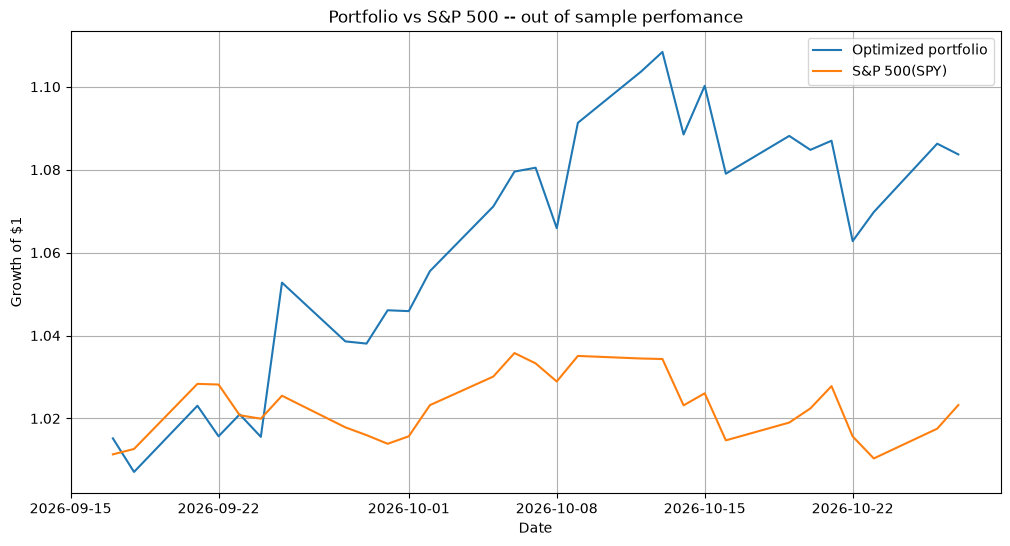

In [187]:
##Let's see how KSh 100 (or $100) invested in each strategy would have grown over the testing period.

cumulative_comparison=(1+comparison).cumprod()
plt.figure(figsize=(12,6))

plt.plot(
    cumulative_comparison['Portfolio'],
    label='Optimized portfolio'
)
plt.plot(
    cumulative_comparison['SPY'],
    label='S&P 500(SPY)'
)

plt.title('Portfolio vs S&P 500 -- out of sample perfomance')
plt.xlabel('Date')
plt.ylabel('Growth of $1')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#actual cumulative returns
portfolio_total_return=cumulative_comparison['Portfolio'].iloc[-1] -1
spy_total_return=cumulative_comparison['SPY'].iloc[-1] -1

print(f'Portfolio return:{portfolio_total_return:.2%}')
print(f'SPY return:{spy_total_return:.2%}')

Portfolio return:8.37%
SPY return:2.32%


In [ ]:
excess_return=portfolio_total_return-spy_total_return

print(f'Portfolio outperfomance:{excess_return:.2%}')

Portfolio outperfomance:6.04%


## BETA
# Beta measures the relationship between your portfolio's returns and the benchmark's returns.
# Beta = 1: Portfolio tends to move in line with the market.
# Beta > 1: Portfolio tends to move more than the market.
# Beta < 1: Portfolio tends to move less than the market.
# Beta < 0: Portfolio tends to move in the opposite direction.

# beta=covariance(return of portfolio,return of benchmark)/variance of benchmark

In [ ]:
portfolio_beta = (
    comparison["Portfolio"].cov(comparison["SPY"])
    / comparison["SPY"].var()
)

print("Portfolio Beta:", portfolio_beta)

Portfolio Beta: 1.4424449450609584


## A beta of 1.44 suggests that, historically, for every 1% movement in SPY, your portfolio moved approximately 1.44% in the same direction on average.

## JENSEN's ALPHA
Jensen's alpha measures the portfolio's return beyond what the CAPM model would predict for its level of market risk
 alpha= return of portfolio-[risk free rate+ portfolio beta(return of Market - risk free rate)]

## REMEMBER: CAPM =[risk free rate + portfolio beta(return of MARKET - risk free rate)]

In [ ]:
portfolio_return_aligned = comparison["Portfolio"].mean() * 252
market_return_aligned = comparison["SPY"].mean() * 252

expected_return_aligned = (
    0.04 + portfolio_beta * (market_return_aligned - 0.04)
)

jensens_alpha_aligned = (
    portfolio_return_aligned - expected_return_aligned
)

print(f"Portfolio return: {portfolio_return_aligned:.2%}")
print(f"Market return: {market_return_aligned:.2%}")
print(f"CAPM expected return: {expected_return_aligned:.2%}")
print(f"Jensen's Alpha: {jensens_alpha_aligned:.2%}")

Portfolio return: 72.07%
Market return: 20.51%
CAPM expected return: 27.81%
Jensen's Alpha: 44.26%


## WALK FORWARD BACKTESTING

#

In [ ]:
print('Total observations:',len(daily_returns))
print('First date:',daily_returns.index.min())
print('Last date:',daily_returns.index.max())

Total observations: 100
First date: 2026-06-05 00:00:00
Last date: 2026-10-27 00:00:00


 Step 1: Set up the walk-forward windows

 We'll use:

 60 observations to train the portfolio.
 10 observations to test it on unseen data.
 Move forward by 10 observations and repeat.

 This gives us four testing periods from your 100 observations

In [ ]:
train_size=60
test_size=10

results=[]

for start in range(0,len(daily_returns)-train_size -test_size+1,test_size):
    train=daily_returns.iloc[start:start+train_size]
    test=daily_returns.iloc[start+train_size:start+train_size+test_size]

    print(
        f'Training:{train.index.min().date()} to {train.index.max().date()} |'
        f'Testing:{test.index.min().date()} to {test.index.max().date()}'
    )

Training:2026-06-05 to 2026-08-31 |Testing:2026-09-01 to 2026-09-15
Training:2026-06-22 to 2026-09-15 |Testing:2026-09-16 to 2026-09-29
Training:2026-07-07 to 2026-09-29 |Testing:2026-09-30 to 2026-10-13
Training:2026-07-21 to 2026-10-13 |Testing:2026-10-14 to 2026-10-27


 Now we'll put the optimization inside the loop.
    For each period, the model will:

 Calculate the training covariance matrix.
 Find the portfolio weights that maximize the Sharpe ratio.
 Apply those weights to the next 10 unseen observations.
Record the test-period performance.

In [194]:
# Walk-forward maximum-Sharpe optimization (unconstrained beyond long-only).
walk_forward_results = []

for start in range(0, len(daily_returns) - train_size - test_size + 1, test_size):
    train = daily_returns.iloc[start:start + train_size]
    test = daily_returns.iloc[start + train_size:start + train_size + test_size]

    optimization = optimize_max_sharpe(
        train,
        risk_free_rate=RISK_FREE_RATE,
        periods=TRADING_DAYS,
        max_weight=1.0,
    )
    optimal_weights = optimization["weights"].reindex(daily_returns.columns).to_numpy()

    test_portfolio = test @ optimal_weights
    test_return = annualized_return(test_portfolio, TRADING_DAYS)
    test_volatility = annualized_volatility(test_portfolio, TRADING_DAYS)
    test_sharpe = calculate_sharpe_ratio(
        test_portfolio, risk_free_rate=RISK_FREE_RATE, periods=TRADING_DAYS
    )

    walk_forward_results.append({
        "Training start": train.index.min(),
        "Testing start": test.index.min(),
        "Testing End": test.index.max(),
        "Return": test_return,
        "Volatility": test_volatility,
        "Sharpe": test_sharpe,
        "Weights": optimal_weights,
    })

print("Number of results:", len(walk_forward_results))
walk_forward_df = pd.DataFrame(walk_forward_results)
display(walk_forward_df)

Number of results: 4


,Training start,Testing start,Testing End,Return,Volatility,Sharpe,Weights
0,2026-06-05,2026-09-01,2026-09-15,0.020243,0.101076,-0.195468,"[0.007756, 0.129522, 0.460164, 0.136908, 0.26565]"
1,2026-06-22,2026-09-16,2026-09-29,-0.772211,0.120509,-6.739847,"[0.066127, 0.139511, 0.249473, 0.382149, 0.16274]"
2,2026-07-07,2026-09-30,2026-10-13,1.658982,0.069086,23.434361,"[0.16753, 0.33614, 0.0, 0.48481, 0.011519]"
3,2026-07-21,2026-10-14,2026-10-27,0.302736,0.111042,2.366098,"[0.051241, 0.27748, 0.0, 0.395085, 0.276194]"


In [195]:
walk_forward_results=[]

for start in range(0,len(daily_returns)-train_size-test_size +1 ,test_size):
    train=daily_returns.iloc[start:start+train_size]
    test=daily_returns.iloc[start+train_size:start+train_size+test_size]

    train_cov= train.cov()*252

    def train_return(weights):
        return np.sum(train.mean()*weights)*252

    def negative_sharpe(weights):
        ret=train_return(weights)
        vol=np.sqrt(weights.T @ train_cov @ weights)
        if vol==0:
            return 1e10
        return -(ret -0.04)/vol

    constraints=[
        {'type':'eq','fun':lambda weights:np.sum(weights)-1}
    ]

    result=minimize(
        negative_sharpe,
        initial_weights,
        method='SLSQP',
        bounds=bounds,
        constraints=constraints
    )

    if not result.success:
        print(f'Optimization failed for window {start}:{result.message}')
        continue

    optimal_weights=result.x
    test_portfolio=test @ optimal_weights

    test_return=test_portfolio.mean() * 252
    test_volatility= test_portfolio.std()*np.sqrt(252)
    test_sharpe= (test_return -0.04)/test_volatility

    walk_forward_results.append({
    'Training start':train.index.min(),
    'Testing start':test.index.min(),
    'Testing End':test.index.max(),
    'Return':test_return,
    'Volatility':test_volatility,
    'Sharpe':test_sharpe,
    'Weights':optimal_weights
    })

print("Number of results:", len(walk_forward_results))

walk_forward_df = pd.DataFrame(walk_forward_results)
display(walk_forward_df)

Number of results: 4


,Training start,Testing start,Testing End,Return,Volatility,Sharpe,Weights
0,2026-06-05,2026-09-01,2026-09-15,0.020243,0.101076,-0.195468,"[0.007756, 0.129522, 0.460164, 0.136908, 0.26565]"
1,2026-06-22,2026-09-16,2026-09-29,-0.772211,0.120509,-6.739847,"[0.066127, 0.139511, 0.249473, 0.382149, 0.16274]"
2,2026-07-07,2026-09-30,2026-10-13,1.658982,0.069086,23.434361,"[0.16753, 0.33614, 0.0, 0.48481, 0.011519]"
3,2026-07-21,2026-10-14,2026-10-27,0.302736,0.111042,2.366098,"[0.051241, 0.27748, 0.0, 0.395085, 0.276194]"


In [ ]:
realized_returns=[]

for start in range(0,len(daily_returns)-train_size- test_size+1 ,test_size):
    train=daily_returns.iloc[start:start+train_size]
    test=daily_returns.iloc[start+train_size:start+train_size+test_size]
    weights=walk_forward_results[len(realized_returns)]['Weights']

    test_portfolio=test @ weights
    total_return=(1 + test_portfolio).prod()-1
    realized_returns.append(total_return)

walk_forward_df['realized return'] = realized_returns

display(
    walk_forward_df[
        ['Testing start','Testing End','Return',
         'realized return','Sharpe']
    ]
)

,Testing start,Testing End,Return,realized return,Sharpe
0,2026-09-01,2026-09-15,0.020243,0.000621,-0.195468
1,2026-09-16,2026-09-29,-0.772211,-0.030478,-6.739847
2,2026-09-30,2026-10-13,1.658982,0.067728,23.434361
3,2026-10-14,2026-10-27,0.302736,0.011855,2.366098


 Return: Annualized estimate based on the average daily return, multiplied by 252.
 Realized Return: The actual compounded return over that particular 10-day testing period

## Calculate the overall walk-forward return

In [ ]:
overall_return=np.prod(1+np.array(realized_returns)) -1
print(f'Overall walk forward Return:{overall_return:.2%}')

Overall walk forward Return:4.81%


## VISUALIAZION OF THE STRATEGY PERFOMANCE

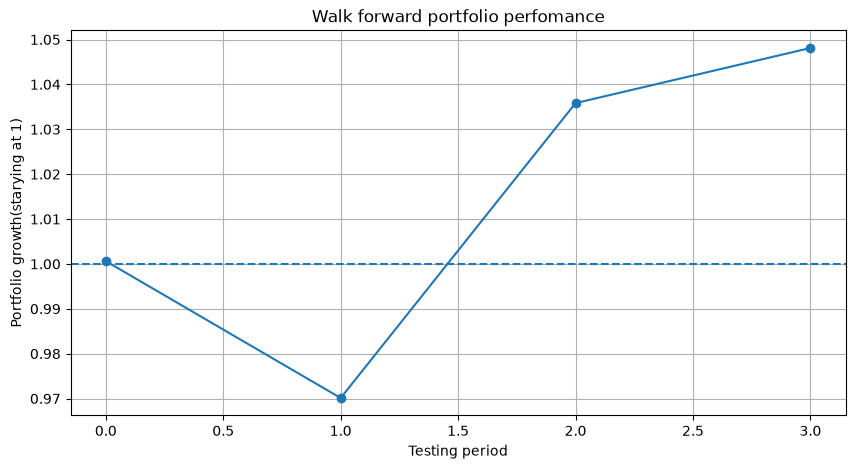

In [198]:
cumulative_walk_forward=(
    1+pd.Series(realized_returns)
).cumprod()

plt.figure(figsize=(10,5))
plt.plot(cumulative_walk_forward,marker='o')
plt.axhline(y=1,linestyle='--')
plt.title('Walk forward portfolio perfomance')
plt.xlabel('Testing period')
plt.ylabel('Portfolio growth(starying at 1)')
plt.grid(True)
plt.show()

## PORTFOLIO TURNOVER

In [ ]:
turnover=[]

previous_weights=initial_weights.copy()

for result in walk_forward_results:
    current_weights=result['Weights']
    portfolio_turnover=0.5 * np.sum(np.abs(current_weights - previous_weights))

    turnover.append(portfolio_turnover)
    previous_weights=current_weights.copy()


print(turnover)

[np.float64(0.3258138720379217), np.float64(0.31360067109181994), np.float64(0.4006941757303606), np.float64(0.26467497414505037)]


 For example, 40.07% turnover means approximately 40.07% of the portfolio's value was traded to move from the previous allocation to the new target allocation.

Our average turnover is approximately 32.62% per rebalancing.

That's fairly substantial. It suggests our optimizer frequently changes its mind about which stocks deserve the most capital.

## TRANSACTION COSTS

In [ ]:
transaction_cost_rate= 0.001
transaction_cost=[
  t * transaction_cost_rate for t in turnover
 ]

print('Transaction costs:',transaction_cost)

Transaction costs: [np.float64(0.00032581387203792174), np.float64(0.00031360067109181995), np.float64(0.0004006941757303606), np.float64(0.0002646749741450504)]


Good. These numbers are the estimated transaction costs for each rebalancing period.

In [201]:
## LETS CALCULATE NET RETURNS
net_returns=[]

for r,cost in zip(realized_returns,transaction_cost):
    net_return=(1+r) * (1 - cost) - 1
    net_returns.append(net_return)

print('Net returns:',net_returns)

net_walk_forward_return = np.prod(
    1 + np.array(net_returns)
) - 1


print('Net walk forward return:',net_walk_forward_return)

Net returns: [np.float64(0.0002949318401090917), np.float64(-0.030782353110757832), np.float64(0.06730002066376084), np.float64(0.01158739781313689)]
Net walk forward return: 0.046741178317527554


## Lets compare the strategy to a buy and hold strategy for exactly the same testing observations

In [202]:
buy_hold_weights=np.repeat(1/len(daily_returns.columns),len(daily_returns.columns))
buy_hold_returns=[]

for start in range(0,len(daily_returns)-train_size- test_size+1,
                   test_size):
    test=daily_returns.iloc[start+train_size:start+train_size + test_size]
    period_returns= test @ buy_hold_weights
    total_return=( 1 + period_returns).prod() -1 
    buy_hold_returns.append(total_return)


print('Buy and hold period returns :',buy_hold_returns)

buy_hold_total_return=np.prod(
    1+ np.array(buy_hold_returns)
) - 1

print(f'Buy and hold overall return:{buy_hold_total_return:.2%}')

Buy and hold period returns : [np.float64(0.013850999691449983), np.float64(-0.01967537274288511), np.float64(0.041820611719564305), np.float64(0.01125520189881879)]
Buy and hold overall return:4.71%


Our buy-and-hold calculation currently resets the portfolio to equal weights at the beginning of each 10-day testing period
That isn't technically a continuous buy-and-hold portfolio.

A true buy-and-hold benchmark should:

Start with 20% invested in each stock at the beginning of the 40-day test.
Allow weights to drift naturally as stock prices change.
Never rebalance between testing periods.

Let's correct that next so we're comparing the strategies fairly.

In [203]:
buy_hold_test_returns = daily_returns.iloc[train_size:]

print("Testing observations:", len(buy_hold_test_returns))
print("First date:", buy_hold_test_returns.index.min())
print("Last date:", buy_hold_test_returns.index.max())

Testing observations: 40
First date: 2026-09-01 00:00:00
Last date: 2026-10-27 00:00:00


In [204]:
buy_hold_weights = np.repeat(
    1 / len(daily_returns.columns),
    len(daily_returns.columns)
)

buy_hold_daily_returns = buy_hold_test_returns @ buy_hold_weights

buy_hold_cumulative = (1 + buy_hold_daily_returns).cumprod()

buy_hold_total_return = buy_hold_cumulative.iloc[-1] - 1

print("Buy-and-hold cumulative return:", buy_hold_total_return)

Buy-and-hold cumulative return: 0.04712314885847624


The corrected buy-and-hold calculation gives +4.7123%, or approximately +4.71%

## COMPARE RISK NOT JUST RETURNS

A strategy that earns slightly less could still be attractive if it takes substantially less risk.

In [205]:
optimized_daily_returns=pd.concat(
    [
        daily_returns.iloc[start+train_size:start+train_size
                           +test_size]
        @ walk_forward_results[i]['Weights']
        for i,start in enumerate(
            range(0,len(daily_returns)- train_size - test_size +1 ,
                  test_size)
        )
    ]
)

optimized_volatility=optimized_daily_returns.std()*np.sqrt(252)

buy_hold_volatility=buy_hold_daily_returns.std() *np.sqrt(252)

print('Optimized strategy volatility:',optimized_volatility)
print('buy and hold volatility:',buy_hold_volatility)

Optimized strategy volatility: 0.11306779603552072
buy and hold volatility: 0.09970016998055935


The optimized strategy had approximately 13.4% more volatility than buy-and-hold.

In [206]:
optimized_return=optimized_daily_returns.mean()*(252)
buy_hold_return=buy_hold_daily_returns.mean()*252

optimized_sharpe=(optimized_return - risk_free_rate)/optimized_volatility
buy_hold_sharpe=(buy_hold_return - risk_free_rate)/buy_hold_volatility
print('Optimized Sharpe:',optimized_sharpe)
print('Buy and hold sharpe:',buy_hold_sharpe)

Optimized Sharpe: 2.321061977310086
Buy and hold sharpe: 2.5587790460753466


We will update the bounds variable not to allow one asset not to be allocated more than 40% of the funds

In [ ]:
bounds = tuple((0, 0.40) for _ in range(num_assets))

In [208]:
# Walk-forward maximum-Sharpe optimization with a 40% maximum asset weight.
walk_forward_results_capped = []

for start in range(0, len(daily_returns) - train_size - test_size + 1, test_size):
    train = daily_returns.iloc[start:start + train_size]
    test = daily_returns.iloc[start + train_size:start + train_size + test_size]

    optimization = optimize_max_sharpe(
        train,
        risk_free_rate=RISK_FREE_RATE,
        periods=TRADING_DAYS,
        max_weight=0.40,
    )
    optimal_weights = optimization["weights"].reindex(daily_returns.columns).to_numpy()

    test_portfolio = test @ optimal_weights
    test_return = annualized_return(test_portfolio, TRADING_DAYS)
    test_volatility = annualized_volatility(test_portfolio, TRADING_DAYS)
    test_sharpe = calculate_sharpe_ratio(
        test_portfolio, risk_free_rate=RISK_FREE_RATE, periods=TRADING_DAYS
    )

    walk_forward_results_capped.append({
        "Training Start": train.index.min(),
        "Testing Start": test.index.min(),
        "Testing End": test.index.max(),
        "Return": test_return,
        "Volatility": test_volatility,
        "Sharpe": test_sharpe,
        "Weights": optimal_weights,
    })

print("Number of successful windows:", len(walk_forward_results_capped))

Number of successful windows: 4


 Examine the new portfolio weights

In [209]:
capped_weights_df = pd.DataFrame(
    [result["Weights"] for result in walk_forward_results_capped],
    columns=daily_returns.columns,
    index=[f"Window {i+1}" for i in range(len(walk_forward_results_capped))]
)

print((capped_weights_df * 100).round(2))

           AAPL   MSFT    JPM    XOM     KO
Window 1   2.16  13.73  40.00  16.07  28.04
Window 2   6.61  13.95  24.94  38.22  16.28
Window 3  18.48  33.40   0.00  40.00   8.13
Window 4   5.13  27.75   0.00  39.51  27.61


Let's calculate the capped strategy's actual returns

In [210]:
realized_returns_capped = []

for start in range(
    0,
    len(daily_returns) - train_size - test_size + 1,
    test_size
):
    test = daily_returns.iloc[
        start + train_size:start + train_size + test_size
    ]

    weights = walk_forward_results_capped[
        len(realized_returns_capped)
    ]["Weights"]

    test_portfolio = test @ weights

    total_return = (1 + test_portfolio).prod() - 1

    realized_returns_capped.append(total_return)


print("Capped period returns:")
print(np.array(realized_returns_capped) * 100)

capped_gross_return = (
    np.prod(1 + np.array(realized_returns_capped)) - 1
)

print("Capped total return:", capped_gross_return * 100, "%")

Capped period returns:
[ 0.29398988 -3.04772444  6.41213401  1.18524386]
Capped total return: 4.698690757648705 %


In [211]:
turnover_capped = []

previous_weights = initial_weights.copy()

for result in walk_forward_results_capped:
    current_weights = result["Weights"]

    portfolio_turnover = 0.5 * np.sum(
        np.abs(current_weights - previous_weights)
    )

    turnover_capped.append(portfolio_turnover)

    previous_weights = current_weights.copy()

print("Capped turnover (%):")
print(np.array(turnover_capped) * 100)

print("Average turnover:",
      np.mean(turnover_capped) * 100, "%")

Capped turnover (%):
[28.04021057 26.82759411 33.08468561 19.48561136]
Average turnover: 26.859525410521368 %


In [212]:
transaction_cost_rate = 0.001

transaction_costs_capped = [
    turnover * transaction_cost_rate
    for turnover in turnover_capped
]

net_returns_capped = [
    (1 + r) * (1 - cost) - 1
    for r, cost in zip(
        realized_returns_capped,
        transaction_costs_capped
    )
]

capped_net_return = (
    np.prod(1 + np.array(net_returns_capped)) - 1
)

print("Capped net period returns (%):")
print(np.array(net_returns_capped) * 100)

print("Capped net total return:",
      capped_net_return * 100, "%")

Capped net period returns (%):
[ 0.26586724 -3.0737344   6.37692789  1.1655273 ]
Capped net total return: 4.5862492891171724 %


# Minimum variance strategy

walk-forward optimizer

In [213]:
# Walk-forward minimum-variance optimization.
walk_forward_min_variance = []

for start in range(0, len(daily_returns) - train_size - test_size + 1, test_size):
    train = daily_returns.iloc[start:start + train_size]
    test = daily_returns.iloc[start + train_size:start + train_size + test_size]

    optimization = optimize_minimum_variance(
        train,
        periods=TRADING_DAYS,
        max_weight=0.40,
    )
    optimal_weights = optimization["weights"].reindex(daily_returns.columns).to_numpy()

    test_portfolio = test @ optimal_weights
    test_return = annualized_return(test_portfolio, TRADING_DAYS)
    test_volatility = annualized_volatility(test_portfolio, TRADING_DAYS)
    test_sharpe = calculate_sharpe_ratio(
        test_portfolio, risk_free_rate=RISK_FREE_RATE, periods=TRADING_DAYS
    )

    walk_forward_min_variance.append({
        "Training Start": train.index.min(),
        "Testing Start": test.index.min(),
        "Testing End": test.index.max(),
        "Return": test_return,
        "Volatility": test_volatility,
        "Sharpe": test_sharpe,
        "Weights": optimal_weights,
    })

print("Successful windows:", len(walk_forward_min_variance))

Successful windows: 4


let's inspect how the optimizer distributed the capital.

In [214]:
min_variance_weights_df = pd.DataFrame(
    [result["Weights"] for result in walk_forward_min_variance],
    columns=daily_returns.columns,
    index=[
        f"Window {i+1}"
        for i in range(len(walk_forward_min_variance))
    ]
)

print((min_variance_weights_df * 100).round(2))

           AAPL  MSFT    JPM    XOM     KO
Window 1  12.46  5.14  39.26  21.47  21.66
Window 2   7.55  3.84  40.00  24.73  23.87
Window 3  10.84  3.97  37.06  20.95  27.18
Window 4   8.63  5.74  34.65  21.59  29.39


Let's calculate realized returns

In [215]:
realized_returns_min_variance = []

for start in range(
    0,
    len(daily_returns) - train_size - test_size + 1,
    test_size
):
    test = daily_returns.iloc[
        start + train_size:start + train_size + test_size
    ]

    weights = walk_forward_min_variance[
        len(realized_returns_min_variance)
    ]["Weights"]

    test_portfolio = test @ weights

    total_return = (1 + test_portfolio).prod() - 1

    realized_returns_min_variance.append(total_return)


print("Minimum-variance period returns (%):")
print(np.array(realized_returns_min_variance) * 100)

min_variance_total_return = (
    np.prod(1 + np.array(realized_returns_min_variance)) - 1
)

print("Minimum-variance total return:",
      min_variance_total_return * 100, "%")

Minimum-variance period returns (%):
[ 1.21992    -3.56051086  2.90951332  1.59884585]
Minimum-variance total return: 2.062262076531396 %


calculate minimum-variance turnover

In [216]:
turnover_min_variance = []

previous_weights = initial_weights.copy()

for result in walk_forward_min_variance:
    current_weights = result["Weights"]

    portfolio_turnover = 0.5 * np.sum(
        np.abs(current_weights - previous_weights)
    )

    turnover_min_variance.append(portfolio_turnover)

    previous_weights = current_weights.copy()

print("Minimum-variance turnover (%):")
print(np.array(turnover_min_variance) * 100)

print(
    "Average turnover:",
    np.mean(turnover_min_variance) * 100,
    "%"
)

Minimum-variance turnover (%):
[22.3944341   6.21344123  6.72524223  4.61840508]
Average turnover: 9.987880659258554 %


Let's calculate transaction costs

In [217]:
transaction_costs_min_variance = [
    turnover * 0.001
    for turnover in turnover_min_variance
]

net_returns_min_variance = [
    (1 + r) * (1 - cost) - 1
    for r, cost in zip(
        realized_returns_min_variance,
        transaction_costs_min_variance
    )
]

min_variance_net_return = (
    np.prod(1 + np.array(net_returns_min_variance)) - 1
)

print("Minimum-variance net period returns (%):")
print(np.array(net_returns_min_variance) * 100)

print(
    "Minimum-variance net total return:",
    min_variance_net_return * 100,
    "%"
)

Minimum-variance net period returns (%):
[ 1.19725237 -3.56650307  2.9025924   1.5941536 ]
Minimum-variance net total return: 2.0214916978077424 %


# compare realized risk

In [218]:
# Calculate daily portfolio returns for each strategy

# Maximum Sharpe, unconstrained
returns_max_sharpe = []

for i, start in enumerate(range(0, len(daily_returns) - train_size - test_size + 1, test_size)):
    test = daily_returns.iloc[start + train_size:start + train_size + test_size]
    weights = walk_forward_results[i]["Weights"]
    returns_max_sharpe.extend((test @ weights).tolist())


# Maximum Sharpe, 40% cap
returns_capped = []

for i, start in enumerate(range(0, len(daily_returns) - train_size - test_size + 1, test_size)):
    test = daily_returns.iloc[start + train_size:start + train_size + test_size]
    weights = walk_forward_results_capped[i]["Weights"]
    returns_capped.extend((test @ weights).tolist())


# Minimum variance, 40% cap
returns_min_variance = []

for i, start in enumerate(range(0, len(daily_returns) - train_size - test_size + 1, test_size)):
    test = daily_returns.iloc[start + train_size:start + train_size + test_size]
    weights = walk_forward_min_variance[i]["Weights"]
    returns_min_variance.extend((test @ weights).tolist())


print("Maximum Sharpe volatility:", np.std(returns_max_sharpe, ddof=1) * np.sqrt(252))
print("Capped Sharpe volatility:", np.std(returns_capped, ddof=1) * np.sqrt(252))
print("Minimum variance volatility:", np.std(returns_min_variance, ddof=1) * np.sqrt(252))

Maximum Sharpe volatility: 0.11306779603552072
Capped Sharpe volatility: 0.11116449259044053
Minimum variance volatility: 0.1141441098241227


calculate realized Sharpe ratios

In [219]:
risk_free_rate = 0.04

strategies = {
    "Maximum Sharpe": returns_max_sharpe,
    "Capped Sharpe": returns_capped,
    "Minimum Variance": returns_min_variance
}

for name, returns in strategies.items():
    daily_returns_array = np.array(returns)

    annual_return = daily_returns_array.mean() * 252
    annual_volatility = daily_returns_array.std(ddof=1) * np.sqrt(252)

    sharpe = (annual_return - risk_free_rate) / annual_volatility

    print(name, "Sharpe:", round(sharpe, 3))

Maximum Sharpe Sharpe: 2.321
Capped Sharpe Sharpe: 2.298
Minimum Variance Sharpe: 0.832


# Let's build a consolidated performance table

In [220]:
performance_summary = pd.DataFrame({
    "Strategy": [
        "Maximum Sharpe",
        "Capped Maximum Sharpe",
        "Minimum Variance"
    ],
    "Net Return (%)": [
        4.6741,
        4.5862,
        2.0215
    ],
    "Realized Volatility (%)": [
        11.3068,
        11.1164,
        11.4144
    ],
    "Sharpe Ratio": [
        2.321,
        2.298,
        0.832
    ],
    "Average Turnover (%)": [
        32.62,
        26.86,
        9.99
    ]
})

performance_summary.set_index("Strategy", inplace=True)

display(performance_summary.round(3))

C:\Users\PC\AppData\Local\Temp\ipykernel_7668\2501831785.py:29: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  performance_summary.set_index("Strategy", inplace=True)


,Net Return (%),Realized Volatility (%),Sharpe Ratio,Average Turnover (%)
Strategy,,,,
Maximum Sharpe,4.674,11.307,2.321,32.62
Capped Maximum Sharpe,4.586,11.116,2.298,26.86
Minimum Variance,2.022,11.414,0.832,9.99


## WEIGHT DRIFT



Set initial weights

In [221]:
print(initial_weights)
print('Total:',initial_weights.sum())

[0.2 0.2 0.2 0.2 0.2]
Total: 1.0


Simulate one day of stock returns.These are hypothetical returns to help us understand the mechanics.

In [ ]:
daily_stock_returns=np.array([
    0.02,#AAPL rises 2%
    0.01,    # MSFT rises 1%
    -0.01,   # JPM falls 1%
    0.03,    # XOM rises 3%
    0.00     # KO unchanged
])

Calculate the new weights

In [223]:
new_values=initial_weights*(1 + daily_stock_returns)

new_weights= new_values/new_values.sum()

print("Original weights:")
print(initial_weights)

print("\nNew weights:")
print(new_weights.round(4))

print("\nTotal:")
print(new_weights.sum())


Original weights:
[0.2 0.2 0.2 0.2 0.2]

New weights:
[0.202 0.2   0.196 0.204 0.198]

Total:
1.0


## Calculate how weights drift over 10 trading days

In [224]:
print(walk_forward_results)

[{'Training start': Timestamp('2026-06-05 00:00:00'), 'Testing start': Timestamp('2026-09-01 00:00:00'), 'Testing End': Timestamp('2026-09-15 00:00:00'), 'Return': np.float64(0.02024300149800203), 'Volatility': np.float64(0.10107558673828515), 'Sharpe': np.float64(-0.19546756184710296), 'Weights': array([0.00775579, 0.12952197, 0.46016426, 0.13690837, 0.26564961])}, {'Training start': Timestamp('2026-06-22 00:00:00'), 'Testing start': Timestamp('2026-09-16 00:00:00'), 'Testing End': Timestamp('2026-09-29 00:00:00'), 'Return': np.float64(-0.7722114538991995), 'Volatility': np.float64(0.12050888449695549), 'Sharpe': np.float64(-6.7398470850480665), 'Weights': array([0.06612652, 0.1395112 , 0.24947333, 0.38214909, 0.16273987])}, {'Training start': Timestamp('2026-07-07 00:00:00'), 'Testing start': Timestamp('2026-09-30 00:00:00'), 'Testing End': Timestamp('2026-10-13 00:00:00'), 'Return': np.float64(1.6589821395033102), 'Volatility': np.float64(0.06908582323799047), 'Sharpe': np.float64(2

In [225]:
# Get the first window's optimized weights
starting_weights=walk_forward_results[0]['Weights']

#Get the first 10 day testing period
first_test=daily_returns.iloc[train_size:train_size+test_size]

# calculate how each asset grows over the 10 days
asset_growth=(1+first_test).prod()

# calculate each assets ending portfolio value
ending_values=starting_weights*asset_growth

#calculate the new portfolio weights

ending_weights=ending_values/ending_values.sum()

#Display the comparison
weight_comparison =pd.DataFrame({
    'Starting weight':starting_weights,
    'Ending weight':ending_weights
},index=daily_returns.columns)

display((weight_comparison*100).round(2))

print("Starting total:", starting_weights.sum())
print("Ending total:", ending_weights.sum())


,Starting weight,Ending weight
AAPL,0.78,0.81
MSFT,12.95,12.69
JPM,46.02,45.54
XOM,13.69,14.40
KO,26.56,26.57


Starting total: 1.0000000000000002
Ending total: 1.0


In [226]:
# Target allocation from the second walk forward window
new_target_weights=walk_forward_results[1]['Weights']

#Actual allocation after the first 10-day window
actual_weights=ending_weights

##calculate the difference
weight_changes=new_target_weights-actual_weights

#calculate one-way turnover
actual_turnover=0.5* np.sum(np.abs(weight_changes))
rebalance_table=pd.DataFrame({
    'Actual Weight (%)':actual_weights*100,
    'New Target (%)':new_target_weights*100,
    'Trade Required (pp)':weight_changes*100
},index=daily_returns.columns)

display(rebalance_table.round(2))
print(f'Actual turnover:{actual_turnover:.2%}')

,Actual Weight (%),New Target (%),Trade Required (pp)
AAPL,0.81,6.61,5.80
MSFT,12.69,13.95,1.26
JPM,45.54,24.95,-20.59
XOM,14.40,38.21,23.82
KO,26.57,16.27,-10.29


Actual turnover:30.88%


Understand what 30.88% means

Your portfolio needs to trade an amount equivalent to 30.88% of its value to move from its drifted allocation to the new target allocation

## Calculate the transaction cost

In [227]:
transaction_cost_rte=0.001
#calculate transaction cost as a proportion of portfolio value

rebalance_cost=actual_turnover*transaction_cost_rte

print(f'Actual turnover:{actual_turnover:.2%}')
print(f'Transaction cost:{rebalance_cost:.2%}')

Actual turnover:30.88%
Transaction cost:0.03%


For example, with a portfolio worth KSh 100,000, the estimated rebalancing cost would be approximately KSh 30.88

## Apply the transaction cost to portfolio value

In [228]:
#Assume the portfolio starts with a value of 100000
portfolio_value= 100000

#Deduct the rebalancin transaction cost
portfolio_value_after_cost=portfolio_value * (1- rebalance_cost)

print(f"Portfolio before rebalancing: KSh {portfolio_value:,.2f}")
print(f"Transaction cost: KSh {portfolio_value * rebalance_cost:,.2f}")
print(f"Portfolio after rebalancing: KSh {portfolio_value_after_cost:,.2f}")

Portfolio before rebalancing: KSh 100,000.00
Transaction cost: KSh 30.88
Portfolio after rebalancing: KSh 99,969.12


Transaction costs reduce the capital available for investment. The next window therefore starts with slightly less money, even though the portfolio has returned to its new target allocation.

## Apply the second testing window's returns

In [229]:
# Get the second testing window
second_test = daily_returns.iloc[
    train_size + test_size : train_size + 2 * test_size
]

# New target weights from the second optimization
new_target_weights = walk_forward_results[1]["Weights"]

# Calculate daily portfolio returns
second_portfolio_returns = second_test @ new_target_weights

# Calculate portfolio value over the second window
portfolio_values = portfolio_value_after_cost * (
    1 + second_portfolio_returns
).cumprod()

print("Portfolio value after each trading day:")
display(portfolio_values.round(2))

print(f"\nEnding portfolio value: KSh {portfolio_values.iloc[-1]:,.2f}")

Portfolio value after each trading day:


Date
2026-09-16    98038.73
2026-09-17    98386.44
2026-09-18    98382.19
2026-09-21    97411.70
2026-09-22    96864.94
2026-09-23    97203.44
2026-09-24    97395.86
2026-09-25    97907.31
2026-09-28    97547.41
2026-09-29    96922.23
dtype: float64


Ending portfolio value: KSh 96,922.23


## calculate the actual asset-level holdings

In [230]:
second_start_values = portfolio_value_after_cost * new_target_weights

holdings_table = pd.DataFrame({
    "Target Weight (%)": new_target_weights * 100,
    "Starting Investment (KSh)": second_start_values
}, index=daily_returns.columns)

display(holdings_table.round(2))

print(
    "Total invested:",
    round(second_start_values.sum(), 2)
)

,Target Weight (%),Starting Investment (KSh)
AAPL,6.61,6610.61
MSFT,13.95,13946.81
JPM,24.95,24939.63
XOM,38.21,38203.11
KO,16.27,16268.96


Total invested: 99969.12


## Track each stock's value over the 10 days

In [231]:
# Calculate cumulative growth of each stock during the second window
second_asset_growth = (1 + second_test).cumprod()

# Calculate the value of each holding over time
second_holdings_values = second_asset_growth.mul(second_start_values, axis=1)

# Calculate total portfolio value each day
realistic_portfolio_values = second_holdings_values.sum(axis=1)

print("Portfolio value without daily rebalancing:")
display(realistic_portfolio_values.round(2))

print(
    "\nEnding portfolio value:",
    f"KSh {realistic_portfolio_values.iloc[-1]:,.2f}"
)

Portfolio value without daily rebalancing:


Date
2026-09-16    98038.73
2026-09-17    98390.47
2026-09-18    98382.97
2026-09-21    97437.67
2026-09-22    96865.65
2026-09-23    97182.30
2026-09-24    97365.76
2026-09-25    97895.72
2026-09-28    97509.61
2026-09-29    96882.51
dtype: float64


Ending portfolio value: KSh 96,882.51


In [232]:
# ============================================================
# REALISTIC WALK-FORWARD PORTFOLIO BACKTEST
# ============================================================

# -----------------------------
# 1. BACKTEST SETTINGS
# -----------------------------

initial_capital = 100_000
risk_free_rate = 0.04
transaction_cost_rate = 0.001  # 0.1% of one-way traded value
trading_days = 252

assets = daily_returns.columns
number_of_assets = len(assets)

# Confirm that the data and optimization results are available
assert len(walk_forward_results) > 0, "No walk-forward optimization results found."
assert len(walk_forward_results) == 4, "Expected four walk-forward windows."

# -----------------------------
# 2. INITIALIZE PORTFOLIO
# -----------------------------

portfolio_value = initial_capital
previous_weights = np.array(initial_weights, dtype=float)

daily_net_returns = []
daily_portfolio_values = []
rebalance_records = []
window_records = []

# -----------------------------
# 3. WALK-FORWARD ACCOUNTING
# -----------------------------

for window_number, result in enumerate(walk_forward_results):

    # Identify the testing period
    start = window_number * test_size + train_size
    end = start + test_size

    test = daily_returns.iloc[start:end].copy()

    # Optimized target weights for this window
    target_weights = np.asarray(result["Weights"], dtype=float)

    # Ensure weights are valid and aligned
    target_weights = target_weights / target_weights.sum()

    # --------------------------------
    # 3A. Calculate actual turnover
    # --------------------------------

    if window_number == 0:
        # First rebalance: from initial portfolio allocation
        pretrade_weights = previous_weights.copy()
    else:
        # Later rebalances: use actual drifted ending weights
        pretrade_weights = previous_weights.copy()

    turnover = 0.5 * np.sum(
        np.abs(target_weights - pretrade_weights)
    )

    transaction_cost = turnover * transaction_cost_rate

    # Deduct transaction costs from portfolio capital
    value_before_rebalance = portfolio_value
    portfolio_value *= (1 - transaction_cost)

    # --------------------------------
    # 3B. Allocate capital to assets
    # --------------------------------

    holdings = portfolio_value * target_weights

    # --------------------------------
    # 3C. Hold assets without trading
    # --------------------------------

    # Each asset's value changes with its daily return.
    growth = (1 + test).cumprod()

    holdings_over_time = growth.mul(holdings, axis=1)

    # Total portfolio value each day
    values = holdings_over_time.sum(axis=1)

    # Daily returns include the transaction cost on
    # the first day of each window.
    previous_day_value = value_before_rebalance

    window_daily_returns = []

    for day_number, date in enumerate(test.index):

        current_value = values.loc[date]

        if day_number == 0:
            # Includes the rebalance cost
            daily_return = current_value / previous_day_value - 1
        else:
            daily_return = (
                current_value / values.iloc[day_number - 1]
            ) - 1

        window_daily_returns.append(daily_return)

        daily_net_returns.append(daily_return)
        daily_portfolio_values.append(current_value)

    # --------------------------------
    # 3D. Calculate ending weights
    # --------------------------------

    ending_holdings = holdings_over_time.iloc[-1]

    ending_weights = (
        ending_holdings / ending_holdings.sum()
    ).to_numpy()

    # Save rebalance information
    rebalance_records.append({
        "Window": window_number + 1,
        "Turnover (%)": turnover * 100,
        "Transaction Cost (%)": transaction_cost * 100,
        "Transaction Cost (KSh)": value_before_rebalance * transaction_cost,
        "Starting Value (KSh)": value_before_rebalance,
        "Value After Cost (KSh)": value_before_rebalance * (1 - transaction_cost),
        "Ending Value (KSh)": values.iloc[-1]
    })

    # Save performance information for this window
    window_records.append({
        "Window": window_number + 1,
        "Start Date": test.index[0],
        "End Date": test.index[-1],
        "Gross Window Return (%)": (
            values.iloc[-1] /
            (value_before_rebalance * (1 - transaction_cost)) - 1
        ) * 100,
        "Net Window Return (%)": (
            values.iloc[-1] / value_before_rebalance - 1
        ) * 100
    })

    # Carry actual ending weights and portfolio value
    # into the next window.
    previous_weights = ending_weights.copy()
    portfolio_value = values.iloc[-1]


# -----------------------------
# 4. BUILD RESULTS SERIES
# -----------------------------

net_returns = pd.Series(
    daily_net_returns,
    index=daily_returns.index[
        train_size:train_size + len(daily_net_returns)
    ],
    name="Optimized Portfolio"
)

portfolio_values = pd.Series(
    daily_portfolio_values,
    index=net_returns.index,
    name="Portfolio Value"
)

rebalance_table = pd.DataFrame(rebalance_records)
window_table = pd.DataFrame(window_records)


# -----------------------------
# 5. CALCULATE NET PERFORMANCE
# -----------------------------

total_return = (1 + net_returns).prod() - 1

annualized_return = (
    (1 + total_return) ** (trading_days / len(net_returns)) - 1
)

annualized_volatility = (
    net_returns.std() * np.sqrt(trading_days)
)

# Sharpe uses annualized arithmetic mean return, not CAGR.
annualized_mean_return = net_returns.mean() * trading_days

sharpe_ratio = (
    (annualized_mean_return - risk_free_rate) / annualized_volatility
    if annualized_volatility > 0 else np.nan
)

# Drawdown, including initial capital
equity_curve = pd.concat([
    pd.Series(
        [initial_capital],
        index=[net_returns.index[0] - pd.Timedelta(days=1)]
    ),
    portfolio_values
])

running_max = equity_curve.cummax()
drawdowns = equity_curve / running_max - 1
maximum_drawdown = drawdowns.min()

average_turnover = rebalance_table["Turnover (%)"].mean()
total_transaction_costs = rebalance_table[
    "Transaction Cost (KSh)"
].sum()


# -----------------------------
# 6. TRUE EQUAL-WEIGHT BUY-AND-HOLD
# -----------------------------

# Use exactly the same out-of-sample dates
out_of_sample_returns = daily_returns.loc[net_returns.index]

# Initial equal-weight holdings
benchmark_weights = np.array(initial_weights, dtype=float)
benchmark_weights = benchmark_weights / benchmark_weights.sum()

benchmark_initial_holdings = initial_capital * benchmark_weights

# Let the original holdings grow without rebalancing
benchmark_growth = (1 + out_of_sample_returns).cumprod()

benchmark_holdings = benchmark_growth.mul(
    benchmark_initial_holdings,
    axis=1
)

benchmark_values = benchmark_holdings.sum(axis=1)

benchmark_daily_returns = benchmark_values.pct_change()

# First day's return measured from initial capital
benchmark_daily_returns.iloc[0] = (
    benchmark_values.iloc[0] / initial_capital
) - 1

benchmark_total_return = (
    benchmark_values.iloc[-1] / initial_capital
) - 1

benchmark_annualized_return = (
    (1 + benchmark_total_return)
    ** (trading_days / len(benchmark_daily_returns)) - 1
)

benchmark_volatility = (
    benchmark_daily_returns.std() * np.sqrt(trading_days)
)

# Use arithmetic annualized mean return for the benchmark Sharpe ratio.
benchmark_annualized_mean_return = (
    benchmark_daily_returns.mean() * trading_days
)

benchmark_sharpe = (
    (benchmark_annualized_mean_return - risk_free_rate)
    / benchmark_volatility
    if benchmark_volatility > 0 else np.nan
)

# Include initial capital when calculating benchmark drawdown.
benchmark_equity_curve = pd.concat([
    pd.Series(
        [initial_capital],
        index=[benchmark_values.index[0] - pd.Timedelta(days=1)]
    ),
    benchmark_values
])

benchmark_drawdowns = (
    benchmark_equity_curve / benchmark_equity_curve.cummax()
) - 1

benchmark_maximum_drawdown = benchmark_drawdowns.min()


# -----------------------------
# 7. FINAL PERFORMANCE COMPARISON
# -----------------------------

performance_comparison = pd.DataFrame({
    "Optimized Portfolio": [
        total_return * 100,
        annualized_return * 100,
        annualized_volatility * 100,
        sharpe_ratio,
        maximum_drawdown * 100,
        average_turnover,
        total_transaction_costs
    ],
    "Equal-Weight Buy-and-Hold": [
        benchmark_total_return * 100,
        benchmark_annualized_return * 100,
        benchmark_volatility * 100,
        benchmark_sharpe,
        benchmark_maximum_drawdown * 100,
        0,
        0
    ]
}, index=[
    "Total Return (%)",
    "Annualized CAGR (extrapolated, %)",
    "Annualized Volatility (%)",
    "Sharpe Ratio",
    "Maximum Drawdown (%)",
    "Average Turnover (%)",
    "Transaction Costs (KSh)"
])


# -----------------------------
# 8. DISPLAY FINAL RESULTS
# -----------------------------

print("\n========== WINDOW PERFORMANCE ==========")
display(window_table.round(4))

print("\n========== REBALANCING AND COSTS ==========")
display(rebalance_table.round(4))

print("\n========== FINAL PERFORMANCE COMPARISON ==========")
display(performance_comparison.round(4))

print("\n========== FINAL PORTFOLIO ==========")
print(f"Initial capital: KSh {initial_capital:,.2f}")
print(f"Final portfolio value: KSh {portfolio_value:,.2f}")
print(f"Total net return: {total_return * 100:.2f}%")
print(f"Total transaction costs: KSh {total_transaction_costs:,.2f}")

print("\n========== FINAL PORTFOLIO WEIGHTS ==========")
final_weights = pd.Series(
    previous_weights * 100,
    index=assets,
    name="Final Weight (%)"
)
display(final_weights.round(2))


========== WINDOW PERFORMANCE ==========


C:\Users\PC\AppData\Local\Temp\ipykernel_7668\2311261853.py:326: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(window_table.round(4))


,Window,Start Date,End Date,Gross Window Return (%),Net Window Return (%)
0,1,2026-09-01,2026-09-15,0.0435,0.0109
1,2,2026-09-16,2026-09-29,-3.0876,-3.1175
2,3,2026-09-30,2026-10-13,6.7499,6.7075
3,4,2026-10-14,2026-10-27,1.1198,1.0930



========== REBALANCING AND COSTS ==========


,Window,Turnover (%),Transaction Cost (%),Transaction Cost (KSh),Starting Value (KSh),Value After Cost (KSh),Ending Value (KSh)
0,1,32.5814,0.0326,32.5814,100000.0000,99967.4186,100010.9084
1,2,30.8844,0.0309,30.8878,100010.9084,99980.0206,96893.0794
2,3,39.7500,0.0397,38.5150,96893.0794,96854.5644,103392.1989
3,4,26.4997,0.0265,27.3986,103392.1989,103364.8003,104522.2995



========== FINAL PERFORMANCE COMPARISON ==========


,Optimized Portfolio,Equal-Weight Buy-and-Hold
Total Return (%),4.5223,4.6429
"Annualized CAGR (extrapolated, %)",32.1346,33.0980
Annualized Volatility (%),11.3469,9.9910
Sharpe Ratio,2.1600,2.5118
Maximum Drawdown (%),-4.0801,-2.1397
Average Turnover (%),32.4289,0.0000
Transaction Costs (KSh),129.3828,0.0000



========== FINAL PORTFOLIO ==========
Initial capital: KSh 100,000.00
Final portfolio value: KSh 104,522.30
Total net return: 4.52%
Total transaction costs: KSh 129.38

========== FINAL PORTFOLIO WEIGHTS ==========


AAPL     5.15
MSFT    26.83
JPM      0.00
XOM     40.38
KO      27.64
Name: Final Weight (%), dtype: float64

# Final visualizations

The following charts summarize the out-of-sample backtest. Run the notebook from the top so the optimization windows, portfolio values,
and benchmark are recalculated consistently. The first training slice contains 59 valid
returns because the first pct_change() value is NaN; later training slices contain 60.

1. **Equity curves** compare the optimized strategy with equal-weight buy-and-hold.
2. **Drawdowns** show the percentage decline from each strategy's previous peak.
3. **Rebalancing allocations** show the optimizer's target weights at each test window.
4. **Window returns** compare each window's net portfolio return with the benchmark return.


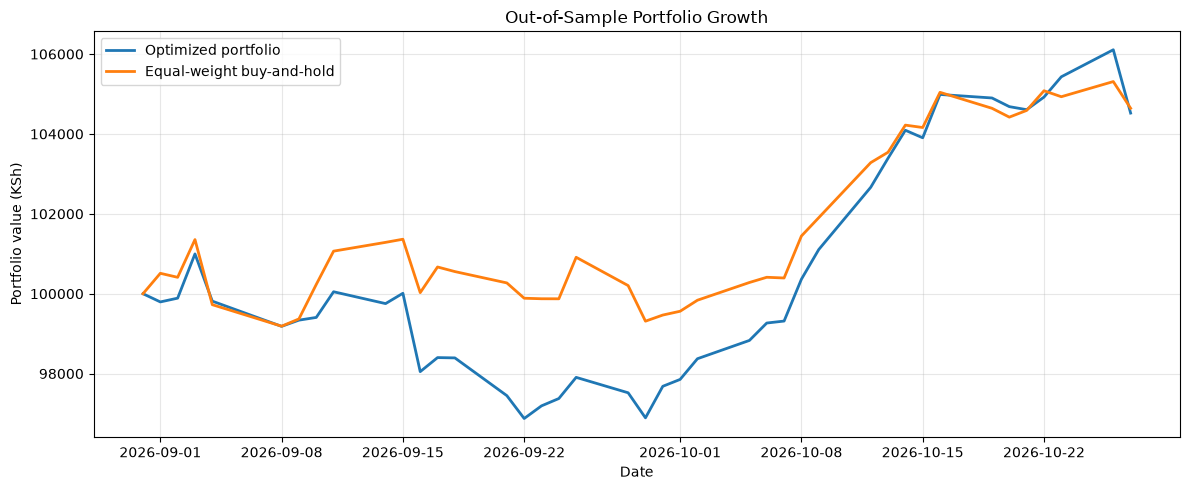

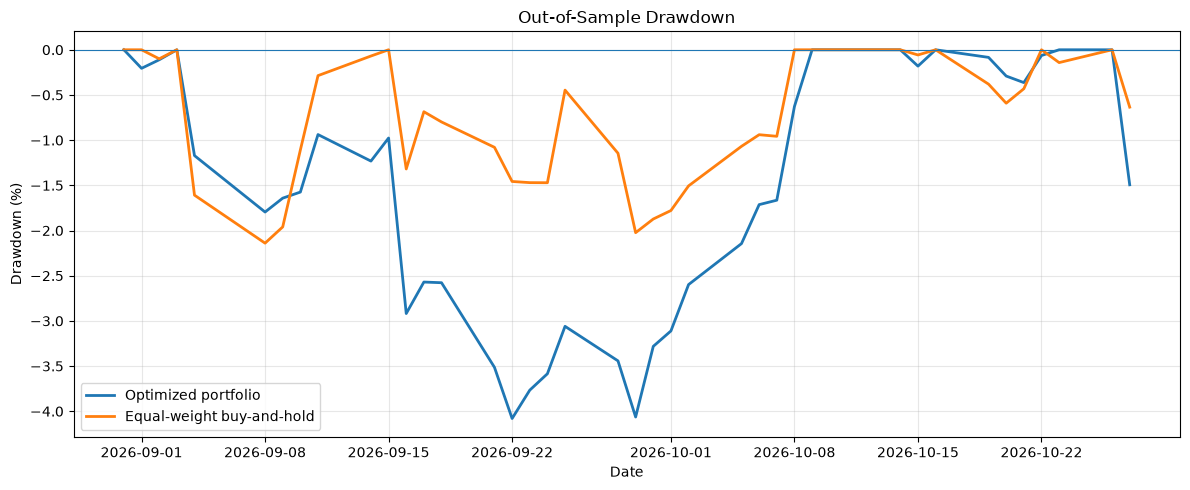

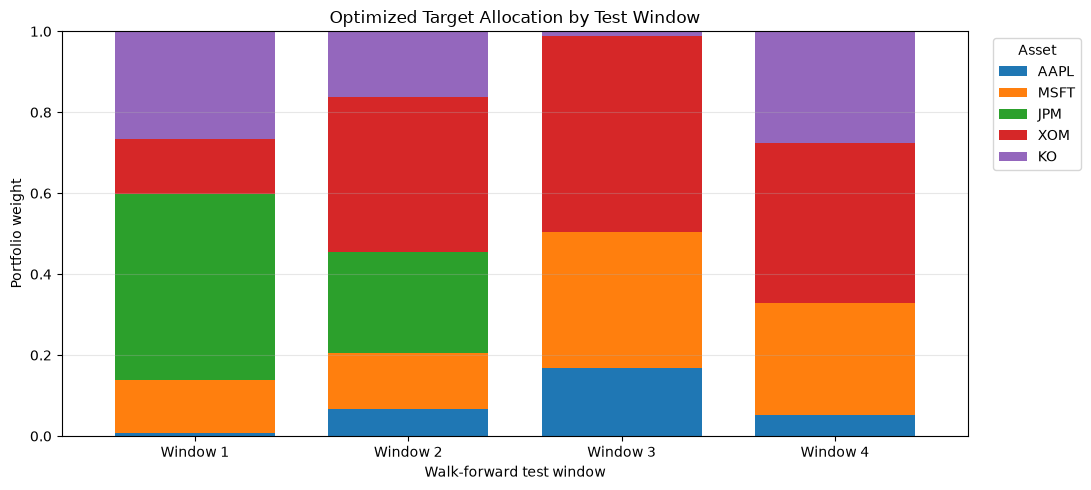

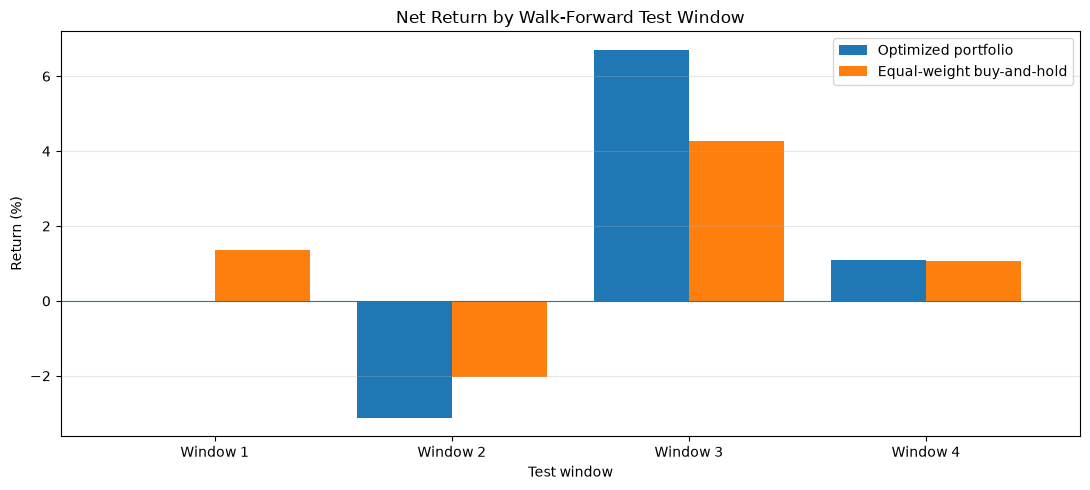

Target allocations by test window:


,AAPL,MSFT,JPM,XOM,KO
Window 1,0.78,12.95,46.02,13.69,26.56
Window 2,6.61,13.95,24.95,38.21,16.27
Window 3,16.75,33.61,0.00,48.48,1.15
Window 4,5.12,27.75,0.00,39.51,27.62


Compounded returns by test window:


,Optimized portfolio,Equal-weight buy-and-hold
Window 1,0.011,1.364
Window 2,-3.117,-2.024
Window 3,6.708,4.258
Window 4,1.093,1.063


In [233]:
# ============================================================
# FINAL VISUALIZATIONS
# ============================================================

# 1. Equity curve: optimized portfolio vs equal-weight benchmark
optimized_equity_curve = pd.concat([
    pd.Series(
        [initial_capital],
        index=[portfolio_values.index[0] - pd.Timedelta(days=1)]
    ),
    portfolio_values
])

plt.figure(figsize=(12, 5))
plt.plot(
    optimized_equity_curve.index,
    optimized_equity_curve.values,
    label="Optimized portfolio",
    linewidth=2
)
plt.plot(
    benchmark_equity_curve.index,
    benchmark_equity_curve.values,
    label="Equal-weight buy-and-hold",
    linewidth=2
)
plt.title("Out-of-Sample Portfolio Growth")
plt.xlabel("Date")
plt.ylabel("Portfolio value (KSh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Drawdown comparison
optimized_drawdowns = (
    optimized_equity_curve / optimized_equity_curve.cummax()
) - 1

plt.figure(figsize=(12, 5))
plt.plot(
    optimized_drawdowns.index,
    optimized_drawdowns.values * 100,
    label="Optimized portfolio",
    linewidth=2
)
plt.plot(
    benchmark_drawdowns.index,
    benchmark_drawdowns.values * 100,
    label="Equal-weight buy-and-hold",
    linewidth=2
)
plt.axhline(0, linewidth=0.8)
plt.title("Out-of-Sample Drawdown")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 3. Target asset allocations by walk-forward test window
allocation_data = pd.DataFrame(
    [np.asarray(result["Weights"], dtype=float)
     for result in walk_forward_results],
    columns=assets,
    index=[f"Window {i+1}" for i in range(len(walk_forward_results))]
)

ax = allocation_data.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 5),
    width=0.75
)
ax.set_title("Optimized Target Allocation by Test Window")
ax.set_xlabel("Walk-forward test window")
ax.set_ylabel("Portfolio weight")
ax.set_ylim(0, 1)
ax.legend(title="Asset", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# 4. Net returns by test window: optimized vs benchmark
optimized_window_returns = []
benchmark_window_returns = []

for window_number in range(len(walk_forward_results)):
    start = window_number * test_size + train_size
    end = start + test_size
    window_dates = daily_returns.index[start:end]

    optimized_window_returns.append(
        (1 + net_returns.loc[window_dates]).prod() - 1
    )
    benchmark_window_returns.append(
        (1 + benchmark_daily_returns.loc[window_dates]).prod() - 1
    )

window_return_comparison = pd.DataFrame({
    "Optimized portfolio": np.array(optimized_window_returns) * 100,
    "Equal-weight buy-and-hold": np.array(benchmark_window_returns) * 100
}, index=[f"Window {i+1}" for i in range(len(walk_forward_results))])

ax = window_return_comparison.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.8
)
ax.set_title("Net Return by Walk-Forward Test Window")
ax.set_xlabel("Test window")
ax.set_ylabel("Return (%)")
ax.axhline(0, linewidth=0.8)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Display the allocation and window-return tables used in the charts.
print("Target allocations by test window:")
display((allocation_data * 100).round(2))

print("Compounded returns by test window:")
display(window_return_comparison.round(3))


## Backtest conclusion

Use the recalculated output above when writing up the project. The key comparison is not
whether the optimizer beats the benchmark in every window, but whether it improves the
risk/return profile over the same out-of-sample dates after transaction costs.

Important limitations:
- The out-of-sample period contains only four test windows (40 trading observations).
- Annualized CAGR is an extrapolation from this short period, not a reliable forecast.
- The first training window has 59 valid daily returns (the first pct_change() value is NaN); subsequent windows have 60. The optimizer is estimated from a short rolling training sample, so weights may be unstable.
- Transaction costs are modeled as a fixed 0.1% of one-way traded notional; taxes, spreads,
  market impact, liquidity constraints, and execution slippage are not modeled.
- The benchmark is an equal-weight buy-and-hold portfolio over the same out-of-sample dates.

Do not claim that the strategy is profitable or robust based on this short backtest alone.
